# Who Gets Heard in Kenya's Counties? Predicting Citizen Contact with MCAs

**Machine Learning Summative Project:** traditional ML (Scikit-Learn) vs deep learning (TensorFlow/Keras)

---

### The problem
Kenya's 2010 Constitution (Art. 1, 10, 174, 196) and the County Governments Act (s.87–92, s.115) require county assemblies to involve the public in law-making and budgeting. In practice, participation is often a box-ticking exercise. Hearings are held far from villages, budget documents are written in complex legal English, and internet data is expensive. The 2024 Finance Bill protests showed how many Kenyans, especially young people, feel unheard. The **Member of County Assembly (MCA)** is the elected representative closest to citizens, so whether a citizen can reach their MCA is a basic test of inclusion.

### The machine-learning question
> **Given a Kenyan citizen's circumstances (where they live, how far they are from services, their digital access, the language they speak, their poverty level) and the budget openness of their county, can we predict whether they contacted their MCA in the past year?**

This is a **binary classification** task. A model that predicts *who is unlikely to engage* tells county governments, county assemblies and civil society **where to send outreach** such as SMS/USSD participation, Swahili and local-language bill summaries, and ward-level barazas, instead of waiting for citizens to come to county headquarters.

### Why does a Kenya project use data from other African countries?
This is the most important design decision in the project, so it comes first.
- **Kenya alone is too small.** Afrobarometer, the only open survey that asks Kenyans whether they contacted their MCA, interviewed **2,400 Kenyans**. The brief requires at least 20,000 rows, and neural networks need far more than 2,400 examples.
- **The other 29 countries are used as extra training data, not as the subject.** Their citizens answered the *same* question about their local councillors, so they can teach a model general patterns, such as "young women contact representatives less", that also hold in Kenya. This is called **borrowing strength** or **transfer**.
- **Kenya stays the subject.** Every model is **selected and evaluated on Kenyan respondents only**. Experiment 1 tests whether borrowing actually helps: a model trained only on Kenyans vs one trained on Kenya plus Africa, both scored on the same held-out Kenyans.

### Data: five real, open sources at three levels
| Level | Source | What it gives us |
|---|---|---|
| **Kenya, county** (47) | **IBP Kenya, County Budget Transparency Survey 2023** | Which budget documents each county published (incl. public-participation reports and the Citizens Budget), and a 0–100 transparency score |
| **Kenya, county** (47) | **Controller of Budget, County Budget Implementation Review FY 2020/21** | Development-budget absorption, own-source revenue, MCA sitting allowances, pending bills |
| **Individual** | **Afrobarometer Round 9**: 2,400 Kenyans in all 47 counties (+ 29 other countries for training) | **Target** (Q11B: contacted local councillor/MCA), plus rural/urban, distance to services, internet use, poverty, language, education |
| Country | IBP Open Budget Survey 2023 | National budget transparency and public participation scores |
| Country | World Bank World Development Indicators | Internet penetration, mobile subscriptions, % rural, GDP per capita |

`get_data.py` downloads all five and joins them. **No synthetic data.** The county sources describe only 47 counties, so they cannot be the rows of a 20,000-row dataset by themselves. Instead, each Kenyan respondent inherits the scores of the county they live in.

### How to read this notebook
Every code cell has a markdown cell **before** it that explains the concept you are about to use (📘) and why it matters for *this* problem. Key outputs are followed by a **"Reading the output"** note that interprets the result.

## 1. Setup

📘 **Concept: reproducibility.** ML involves randomness in train/test splits, model initialisation and data shuffling. Fixing a **random seed** makes the results repeatable, so anyone who re-runs the notebook gets the same numbers as the report. Set seeds for Python, NumPy and (later) TensorFlow.

We also define one plotting style for every figure, with **Kenya always in orange**. Every chart is saved to `figures/`, and the report uses these exact files.

In [1]:
import os, sys, json, random, subprocess, warnings, time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from cycler import cycler

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", message=".*sklearn.utils.parallel.delayed.*")
warnings.filterwarnings("ignore", module="openpyxl")
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 160)

SEED = 42
os.environ["PYTHONHASHSEED"] = str(SEED)
os.environ["PYTHONWARNINGS"] = "ignore:`sklearn.utils.parallel.delayed`"   # silence a noisy joblib-worker warning
random.seed(SEED)
np.random.seed(SEED)

FIG_DIR, MODEL_DIR, RESULTS_DIR = Path("figures"), Path("models"), Path("results")
for d in (FIG_DIR, MODEL_DIR, RESULTS_DIR):
    d.mkdir(exist_ok=True)

# Colour-blind-safe categorical palette (fixed order) + neutral chart chrome
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
BLUE, ORANGE, AQUA = PALETTE[:3]          # orange = Kenya in every figure
GREY_TEXT = "#52514e"
DIVERGING = LinearSegmentedColormap.from_list("div", ["#2a78d6", "#f0efec", "#e34948"])
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "savefig.facecolor": "#fcfcfb",
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": "#0b0b0b", "text.color": "#0b0b0b",
    "xtick.color": GREY_TEXT, "ytick.color": GREY_TEXT,
    "axes.grid": True, "grid.color": "#e7e6e2", "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.prop_cycle": cycler(color=PALETTE), "lines.linewidth": 2,
    "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold", "figure.dpi": 110,
})

def savefig(name):
    plt.savefig(FIG_DIR / f"{name}.png", dpi=200, bbox_inches="tight")

print("Python", sys.version.split()[0], "| pandas", pd.__version__, "| numpy", np.__version__)

Python 3.12.13 | pandas 3.0.6 | numpy 2.5.4


## 2. Acquire and merge the five data sources

📘 **Concept: multi-level data merging.** Our sources describe three different *units*: **people** (Afrobarometer), **counties** (IBP county survey, Controller of Budget) and **countries** (IBP Open Budget Survey, World Bank). To combine them we do **many-to-one joins**:
- Every respondent receives their **country's** scores, joined on the ISO-3 code (`KEN`, `UGA`, …).
- Every **Kenyan** respondent also receives their **county's** scores, joined on the county name. Names are normalised first, because each source spells them differently ("Nairobi City" vs "Nairobi", "Elgeyo/Marakwet" vs "Elgeyo-Marakwet", "Murang'a" vs "Muranga").

Respondents in other countries have no Kenyan county, so their county columns stay blank. That is honest: we do not invent county scores for Uganda or Ghana.

`get_data.py` uses `validate="many_to_one"` in every `pd.merge`, so pandas raises an error if a county or country appears twice on the right-hand side. That check catches silent row duplication, one of the most common merge bugs. It also stops if any Kenyan county fails to match.

**Timing matters when merging.** Afrobarometer interviewed Kenyans in **November 2021** about contact "in the past year". So we use the Controller of Budget report for **FY 2020/21** (July 2020–June 2021), the budget year citizens had just lived through. The IBP county survey is from 2023, two years later. We assume county transparency changes slowly, and record this as a limitation.

The raw files are **not** committed to GitHub (assignment rule). They live in `data/raw/` locally and in the Google Drive folder.

In [2]:
DATA_PATH = Path("data/processed/citizen_voice_merged.csv")
if not DATA_PATH.exists() or "cbts_transparency_score" not in pd.read_csv(DATA_PATH, nrows=0).columns:
    subprocess.run([sys.executable, "get_data.py"], check=True)

raw = pd.read_csv(DATA_PATH)
print(f"Merged dataset: {raw.shape[0]:,} rows x {raw.shape[1]} columns")
raw.loc[raw.iso3 == "KEN"].head(3)

Merged dataset: 53,444 rows x 73 columns


,respondent_id,urban_rural,region_code,ea_electricity_grid,ea_piped_water,ea_sewage,ea_mobile_service,ea_post_office,ea_school,ea_police_station,ea_health_clinic,ea_market,ea_bank,ea_govt_office,ea_paid_transport,ea_road_tarred,age,pov_food,pov_water,pov_medical,pov_fuel,pov_cash,discuss_politics,efficacy_make_councillor_listen,q11b_contact_councillor,councillors_listen,info_access_local_budget,trust_local_council,corruption_councillors,news_radio,...,freq_internet_use,home_electricity_connected,employment,education,gender,interview_language,survey_weight,country,iso3,region,ibp_transparency,ibp_participation,ibp_oversight,ibp_legislative_oversight,ibp_audit_oversight,wb_gdp_pc_ppp,wb_internet_users_pct,wb_mobile_subs_per100,wb_rural_pop_pct,cbts_docs_published,cbts_pp_reports,cbts_citizens_budget,cbts_transparency_score,cob_dev_absorption_pct,cob_total_absorption_pct,cob_dev_budget_share_pct,cob_osr_target_met_pct,cob_mca_sitting_allowance,cob_mcas,cob_pending_bills_pct
19168,KEN0001,1.0,321.0,1.0,1.0,1.0,1.0,0.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,4.0,48.0,1.0,3.0,3.0,1.0,2.0,1.0,1.0,0.0,1.0,1.0,2.0,1.0,4.0,...,3.0,1.0,2.0,5.0,1.0,1.0,0.508715,Kenya,KEN,Kiambu,55.0,31.0,57.0,47.0,78.0,5691.825135,32.0704,120.612417,68.366966,6.0,0.0,0.0,45.6,54.5,76.3,33.9,63.9,84672.0,93.0,19.59
19169,KEN0002,1.0,321.0,1.0,1.0,1.0,1.0,0.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,4.0,32.0,0.0,0.0,0.0,0.0,3.0,2.0,1.0,0.0,3.0,0.0,0.0,2.0,0.0,...,4.0,1.0,1.0,6.0,2.0,1.0,1.526146,Kenya,KEN,Kiambu,55.0,31.0,57.0,47.0,78.0,5691.825135,32.0704,120.612417,68.366966,6.0,0.0,0.0,45.6,54.5,76.3,33.9,63.9,84672.0,93.0,19.59
19170,KEN0003,1.0,321.0,1.0,1.0,1.0,1.0,0.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,4.0,28.0,4.0,3.0,3.0,4.0,3.0,2.0,0.0,0.0,1.0,0.0,0.0,3.0,4.0,...,4.0,1.0,1.0,3.0,2.0,4.0,1.017431,Kenya,KEN,Kiambu,55.0,31.0,57.0,47.0,78.0,5691.825135,32.0704,120.612417,68.366966,6.0,0.0,0.0,45.6,54.5,76.3,33.9,63.9,84672.0,93.0,19.59


📘 **Concept: provenance checking.** Before modelling, confirm that each source contributed what you expected. A merge that "worked" can still leave a whole source blank if the keys didn't match. We check completeness separately for **Kenyan rows**, because that is where the county data must be complete.

In [3]:
COUNTY_COLS = [c for c in raw.columns if c.startswith(("cbts_", "cob_"))]
groups = {
    "Afrobarometer R9 (individual)": [c for c in raw.columns if not c.startswith(("ibp_", "wb_", "cbts_", "cob_"))],
    "IBP Kenya county survey 2023 (county)": [c for c in raw.columns if c.startswith("cbts_")],
    "Controller of Budget FY2020/21 (county)": [c for c in raw.columns if c.startswith("cob_")],
    "IBP Open Budget Survey 2023 (country)": [c for c in raw.columns if c.startswith("ibp_")],
    "World Bank WDI (country)": [c for c in raw.columns if c.startswith("wb_")],
}
is_ken = raw["iso3"] == "KEN"
print(f"{'source':42s} cols | non-missing: Kenyan rows | other rows")
for name, cols_ in groups.items():
    print(f"{name:42s} {len(cols_):3d}  | {raw.loc[is_ken, cols_].notna().mean().mean():18.1%} | "
          f"{raw.loc[~is_ken, cols_].notna().mean().mean():9.1%}")
print(f"\nKenya: {is_ken.sum():,} respondents in {raw.loc[is_ken, 'region'].nunique()} counties | "
      f"other countries: {(~is_ken).sum():,} respondents in {raw.loc[~is_ken, 'country'].nunique()} countries")

county_table = (raw[is_ken].groupby("region")
                .agg(respondents=("respondent_id", "size"), **{c: (c, "first") for c in COUNTY_COLS})
                .sort_values("respondents", ascending=False))
county_table.head(8).round(1)

source                                     cols | non-missing: Kenyan rows | other rows
Afrobarometer R9 (individual)               53  |             100.0% |    100.0%
IBP Kenya county survey 2023 (county)        4  |             100.0% |      0.0%
Controller of Budget FY2020/21 (county)      7  |             100.0% |      0.0%
IBP Open Budget Survey 2023 (country)        5  |             100.0% |     85.9%
World Bank WDI (country)                     4  |             100.0% |     99.4%

Kenya: 2,400 respondents in 47 counties | other countries: 51,044 respondents in 38 countries


,respondents,cbts_docs_published,cbts_pp_reports,cbts_citizens_budget,cbts_transparency_score,cob_dev_absorption_pct,cob_total_absorption_pct,cob_dev_budget_share_pct,cob_osr_target_met_pct,cob_mca_sitting_allowance,cob_mcas,cob_pending_bills_pct
region,,,,,,,,,,,,
Nairobi City,264,11.0,1.0,0.0,60.5,66.4,79.6,22.4,61.4,67285.0,124.0,143.4
Kiambu,144,6.0,0.0,0.0,45.6,54.5,76.3,33.9,63.9,84672.0,93.0,19.6
Nakuru,112,8.0,0.0,1.0,57.8,48.3,66.2,48.2,90.5,69911.0,79.0,3.5
Kakamega,88,8.0,1.0,0.0,50.9,65.6,78.5,43.7,67.5,98871.0,90.0,3.7
Machakos,80,14.0,2.0,1.0,63.1,54.5,81.2,35.2,99.7,102975.0,61.0,9.1
Meru,80,9.0,0.0,0.0,42.5,70.4,85.5,31.7,72.7,100465.0,69.0,8.5
Bungoma,72,12.0,0.0,1.0,67.9,71.2,81.4,33.7,79.0,11344.0,61.0,0.7
Kilifi,72,4.0,0.0,0.0,35.3,75.9,78.5,36.9,69.4,39380.0,56.0,13.6


> **Reading the output:** All five sources arrived. Every **Kenyan** row is 100% complete for both county sources, so all 47 counties matched. The county columns are 0% filled for other countries, as designed. The IBP national block is 85.9% filled outside Kenya because **6 of the 38 other countries are not covered by the Open Budget Survey 2023**. The county table already shows the variety the merge brings in. Nairobi (264 respondents) carries pending bills worth **143% of its annual budget**, while Machakos published 14 of 16 key budget documents but Kilifi only 4.

## 3. Define the target variable

📘 **Concept: turning a survey question into a label.** Afrobarometer question **Q11B** asks: *"During the past year, how often have you contacted a local government councillor about some important problem or to give them your views?"* In Kenya the local government councillor is the **MCA**. Answers are coded 0 = Never, 1 = Only once, 2 = A few times, 3 = Often, plus **sentinel codes** 8 = Refused, 9 = Don't know, −1 = Missing, and **94 = not asked** (Angola, Liberia, São Tomé and Seychelles have no elected local councillors, so the question was skipped there).

We **binarise**: `contacted = 1` if the person contacted their MCA/councillor at least once, `0` if never. Refused/don't-know/not-asked rows are dropped, because we cannot know their true label and guessing would inject noise into the target.

Why binary rather than 4 classes? The policy question is *"who is excluded?"*. The difference between "a few times" and "often" matters less than the difference between **zero voice and some voice**, and merging the rare upper categories gives more stable estimates.

In [4]:
Q11B_LABELS = {0: "Never", 1: "Only once", 2: "A few times", 3: "Often",
               8: "Refused", 9: "Don't know", 94: "Not asked (no elected local councils)", -1: "Missing"}
print("Kenya, Q11B answers:")
print(raw.loc[is_ken, "q11b_contact_councillor"].map(Q11B_LABELS).value_counts().to_string())

df = raw[raw["q11b_contact_councillor"].isin([0, 1, 2, 3])].copy()
df["contacted"] = (df["q11b_contact_councillor"] > 0).astype(int)
df["is_kenya"] = df["iso3"].eq("KEN")

print(f"\nRows kept: {len(df):,} of {len(raw):,} ({len(raw) - len(df):,} dropped: refused/don't know/not asked)")
print(f"Contact rate, Kenya:           {df.loc[df.is_kenya, 'contacted'].mean():.1%}  (n = {df.is_kenya.sum():,})")
print(f"Contact rate, other countries: {df.loc[~df.is_kenya, 'contacted'].mean():.1%}  (n = {(~df.is_kenya).sum():,})")

Kenya, Q11B answers:
q11b_contact_councillor
Never          1788
Only once       232
A few times     224
Often           155
Don't know        1



Rows kept: 48,515 of 53,444 (4,929 dropped: refused/don't know/not asked)
Contact rate, Kenya:           25.5%  (n = 2,399)
Contact rate, other countries: 27.6%  (n = 46,116)


📘 **Concept: complete-case country coverage.** IBP's Open Budget Survey does not cover every Afrobarometer country. We could fill the missing country scores with an average, but that would invent a governance score for a whole country, which is a form of fabrication. We **drop those training countries** and record how many rows that costs. Kenya is covered, so no Kenyan row is lost.

In [5]:
no_ibp = sorted(df.loc[df["ibp_participation"].isna(), "country"].unique())
print("Countries without an IBP 2023 score:", no_ibp)
before = len(df)
df = df[df["ibp_participation"].notna()].copy()
print(f"Dropped {before - len(df):,} rows -> {len(df):,} rows remain: {df.is_kenya.sum():,} Kenyans + "
      f"{(~df.is_kenya).sum():,} respondents from {df.loc[~df.is_kenya, 'country'].nunique()} other countries")

Countries without an IBP 2023 score: ['Cabo Verde', 'Congo-Brazzaville', 'Gabon', 'Mauritania', 'Mauritius']
Dropped 5,985 rows -> 42,530 rows remain: 2,399 Kenyans + 40,131 respondents from 29 other countries


> **Reading the output:** Only one Kenyan answered "don't know" and nobody refused, so we keep **2,399 Kenyans**. **25.5% of Kenyans contacted their MCA in the past year, about 1 in 4**, close to the 27.6% in the other countries. The classes are therefore **imbalanced (≈75:25)**, which shapes every later choice: metrics (PR-AUC, F1), class weights and threshold tuning. Dropping the training countries without IBP scores leaves **42,530 rows: 2,399 Kenyans + 40,131 respondents from 29 other countries**, more than twice the 20,000-row minimum.

## 4. Clean the survey codes

📘 **Concept: sentinel values.** Surveys encode non-answers as numbers: −1, 8, 9, 94, 98, 998, 9994… If you feed these to a model as if they were real values, a person "aged 998" becomes the oldest person in Kenya. The model learns garbage without raising any error. Always read the **codebook** and convert sentinel codes to `NaN`.

Watch out for three subtleties:
1. **The same number means different things in different questions.** `8` is "Refused" for most items but **"University completed"** for education (Q94). So we clean column by column, never with one global rule.
2. **"Not applicable" is information, not missingness.** Q90G (*does your phone have internet?*) is coded 7 = "not applicable, doesn't own a phone". The true answer is *no internet on a phone*, so we recode 7 → 0.
3. **"Don't know" can be a signal.** A citizen who answers "don't know" to *"do councillors listen?"* may be disconnected from local government altogether. Before deleting these answers we **count** them into a feature.

In [6]:
def keep_valid(series, lo, hi):
    # Anything outside the codebook's valid range (-1, 8, 9, 94, 98, 998, 9994 ...) becomes NaN
    return series.where(series.between(lo, hi))

EA_FLAGS = [c for c in df.columns if c.startswith("ea_") and c != "ea_road_tarred"]
POVERTY = ["pov_food", "pov_water", "pov_medical", "pov_fuel", "pov_cash"]
NEWS = ["news_radio", "news_tv", "news_newspaper", "news_internet", "news_social_media"]
OWN = ["own_radio", "own_tv", "own_vehicle", "own_computer", "own_bank_account", "own_mobile_phone"]
ATTITUDES = ["discuss_politics", "efficacy_make_councillor_listen", "councillors_listen",
             "info_access_local_budget", "trust_local_council", "corruption_councillors",
             "want_local_budgets_public"]

# 1) Count "don't know" (code 9) answers on governance questions BEFORE they become NaN
df["dont_know_governance"] = (df[ATTITUDES] == 9).sum(axis=1)

# 2) "Not applicable" is information: no personal phone => no internet on a phone
df["phone_has_internet"] = df["phone_has_internet"].replace(7, 0)

# 3) Column-specific valid ranges, read from the Afrobarometer R9 codebook
VALID_RANGE = {**{c: (0, 1) for c in EA_FLAGS},                 # 9 = interviewer can't determine
               **{c: (0, 4) for c in POVERTY + NEWS},
               **{c: (0, 2) for c in OWN},
               "freq_mobile_use": (0, 4), "freq_internet_use": (0, 4),
               "phone_has_internet": (0, 1), "home_electricity_connected": (0, 1),
               "employment": (0, 3),                              # 9994 = not asked
               "age": (18, 112),                                  # 998/999 = refused/don't know
               "education": (0, 9),                               # NB: 8 = university completed, a VALID value
               "discuss_politics": (0, 2), "efficacy_make_councillor_listen": (0, 3),
               "councillors_listen": (0, 3), "info_access_local_budget": (0, 3),
               "trust_local_council": (0, 3), "corruption_councillors": (0, 3),
               "want_local_budgets_public": (0, 1)}
before_nan = df[list(VALID_RANGE)].isna().sum().sum()
for c, (lo, hi) in VALID_RANGE.items():
    df[c] = keep_valid(df[c], lo, hi)
print(f"Sentinel codes converted to NaN: {df[list(VALID_RANGE)].isna().sum().sum() - before_nan:,} cells")

# 4) Road surface: 5 = paved/tarred, 6 = concrete -> 1; earth/gravel/etc -> 0
df["ea_road_tarred"] = df["ea_road_tarred"].map(lambda v: np.nan if v == -1 else float(v in (5, 6)))

# 5) Always verify: every cleaned column should now sit inside its codebook range
check = df[list(VALID_RANGE)].agg(["min", "max"]).T
check["% missing (Kenya)"] = df.loc[df.is_kenya, list(VALID_RANGE)].isna().mean().mul(100).round(1)
check["% missing (all)"] = df[list(VALID_RANGE)].isna().mean().mul(100).round(1)
check.sort_values("% missing (Kenya)", ascending=False).head(10)

Sentinel codes converted to NaN: 18,649 cells


,min,max,% missing (Kenya),% missing (all)
corruption_councillors,0.0,3.0,3.6,5.7
info_access_local_budget,0.0,3.0,2.3,4.1
trust_local_council,0.0,3.0,1.5,2.2
efficacy_make_councillor_listen,0.0,3.0,1.0,4.5
own_bank_account,0.0,2.0,0.9,1.4
want_local_budgets_public,0.0,1.0,0.8,2.3
councillors_listen,0.0,3.0,0.6,2.3
own_computer,0.0,2.0,0.4,0.6
news_social_media,0.0,4.0,0.4,1.3
ea_police_station,0.0,1.0,0.3,1.3


> **Reading the output:** 18,649 survey cells were sentinel codes and are now `NaN`. Every column now sits inside its codebook range (e.g. education 0–9, age 18+). Kenyan data is very clean: at most 3.6% missing, and lower than the other countries on every item. Missingness is highest for **attitudes towards MCAs** (corruption, budget information). That pattern is meaningful in itself: people who know little about their county government more often answer "don't know", which is why we kept a `dont_know_governance` count.

## 5. Exploratory Data Analysis (EDA), Kenya first

📘 **Concept: EDA tests your hypotheses before the model does.** The problem statement names three barriers: **distance**, **data cost / digital access**, and **legal English**. EDA checks whether the raw data supports each one. If it doesn't, you have learned something before spending hours on models.

We plot the **contact rate** (the share of people with `contacted = 1`) across groups. With a binary target, a group's mean of the label *is* its rate. Each panel shows **Kenya (orange) next to the other countries (blue)**. If the patterns look alike, that is early evidence that the other countries can teach a model something true about Kenya.

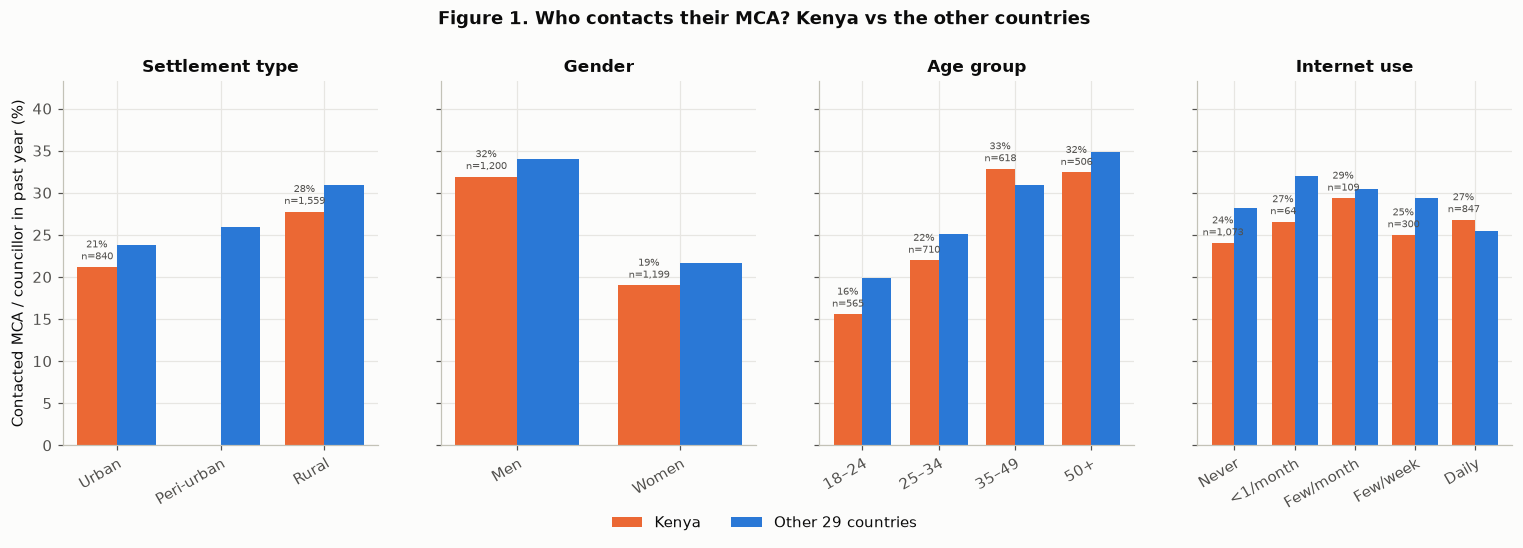

Kenya, contact rate by interview language:
                       rate     n
interview_lang_group             
English               0.280   599
Local language        0.174   178
Swahili               0.254  1622


In [7]:
SETTLEMENT = {1: "Urban", 3: "Peri-urban", 2: "Rural"}
LANG = {1: "English", 2: "French", 3: "Portuguese", 4: "Swahili", 5: "Arabic"}
INTERNET = {0: "Never", 1: "<1/month", 2: "Few/month", 3: "Few/week", 4: "Daily"}
AGE_LABELS = ["18–24", "25–34", "35–49", "50+"]

df["settlement"] = df["urban_rural"].map(SETTLEMENT)
df["interview_lang_group"] = df["interview_language"].map(LANG).fillna("Local language")
df["internet_use_label"] = df["freq_internet_use"].map(INTERNET)
df["age_group"] = pd.cut(df["age"], [17, 24, 34, 49, 120], labels=AGE_LABELS)
df["gender_label"] = df["gender"].map({1: "Men", 2: "Women"})
OTHERS = f"Other {df.loc[~df.is_kenya, 'country'].nunique()} countries"
df["where"] = np.where(df["is_kenya"], "Kenya", OTHERS)

def rate_bars(ax, col, order, title):
    g = df.groupby([col, "where"], observed=True)["contacted"].agg(["mean", "size"]).unstack("where").reindex(order)
    x, w = np.arange(len(order)), 0.38
    for i, (grp, color) in enumerate([("Kenya", ORANGE), (OTHERS, BLUE)]):
        bars = ax.bar(x + (i - 0.5) * w, g[("mean", grp)] * 100, width=w, color=color, label=grp)
        if grp == "Kenya":
            for b, m, n in zip(bars, g[("mean", grp)], g[("size", grp)]):
                if np.isnan(m):   # e.g. Afrobarometer classifies no Kenyan area as peri-urban
                    continue
                ax.text(b.get_x() + b.get_width() / 2, b.get_height() + 0.5, f"{m:.0%}\nn={int(n):,}",
                        ha="center", va="bottom", fontsize=6.5, color=GREY_TEXT)
    ax.set_xticks(x, order)
    ax.set_title(title)
    ax.set_ylim(0, np.nanmax(g.xs("mean", axis=1, level=0).values) * 100 * 1.35)
    plt.setp(ax.get_xticklabels(), rotation=30, ha="right", rotation_mode="anchor")

fig, axes = plt.subplots(1, 4, figsize=(17, 4.3), sharey=True)
rate_bars(axes[0], "settlement", ["Urban", "Peri-urban", "Rural"], "Settlement type")
rate_bars(axes[1], "gender_label", ["Men", "Women"], "Gender")
rate_bars(axes[2], "age_group", AGE_LABELS, "Age group")
rate_bars(axes[3], "internet_use_label", list(INTERNET.values()), "Internet use")
axes[0].set_ylabel("Contacted MCA / councillor in past year (%)")
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, frameon=False, loc="lower center", ncol=2, bbox_to_anchor=(0.5, -0.1))
fig.suptitle("Figure 1. Who contacts their MCA? Kenya vs the other countries", y=1.03, fontweight="bold")
savefig("fig01_contact_rate_kenya_vs_africa")
plt.show()

ken = df[df.is_kenya]
print("Kenya, contact rate by interview language:")
print(ken.groupby("interview_lang_group")["contacted"].agg(rate="mean", n="size").round(3).to_string())

> **Reading the output:** Three lessons, and they shape the whole project.
1. **Kenya looks like the rest of the sample.** In every panel the orange (Kenya) and blue (other countries) bars move together. That is the first evidence that other countries can teach a model about Kenya.
2. **The biggest gaps are social, not physical.** **Young Kenyans aged 18–24 contact their MCA half as often (16%) as those aged 35–49 (33%)**, and **women far less than men (19% vs 32%)**. The Gen Z disconnect behind the 2024 Finance Bill protests is visible here, three years earlier.
3. **The simple barrier story is wrong in one direction.** **Rural** Kenyans contact MCAs *more* than urban ones (28% vs 21%), and internet use makes little difference. By language, Kenyans interviewed in **local languages contact MCAs least (17%)**, against 25% in Swahili and 28% in English. That supports the language barrier, though the local-language group is small (178).

**Why might rural people engage more?** Q11B measures *informal, personal contact* with a ward representative. In a rural ward the MCA is often a neighbour and the gatekeeper to bursaries, roads and water, so people approach them directly. Urban residents are more anonymous and have other channels. The barriers in the problem statement (data cost, distance to *county headquarters*, legal English) block **formal** participation, such as budget hearings and memoranda on bills. Afrobarometer does not measure that directly. **Contact is not the same as influence.** I come back to this distinction in the Discussion section of the report.

📘 **Concept: ecological (group-level) correlation.** Now we zoom out to the **47 counties**. Each point is one county: its observed MCA-contact rate against one county budget indicator. If more open, better-run counties had more engaged citizens, the points would slope upwards. This tells us whether the **county-level sources** are likely to add predictive information.

⚠️ Two cautions. **Ecological fallacy:** a pattern between *counties* doesn't automatically hold for *individuals* inside them. **Small samples:** Afrobarometer interviewed only 8–264 people per county, so each county's rate is noisy. Point size shows the sample size.

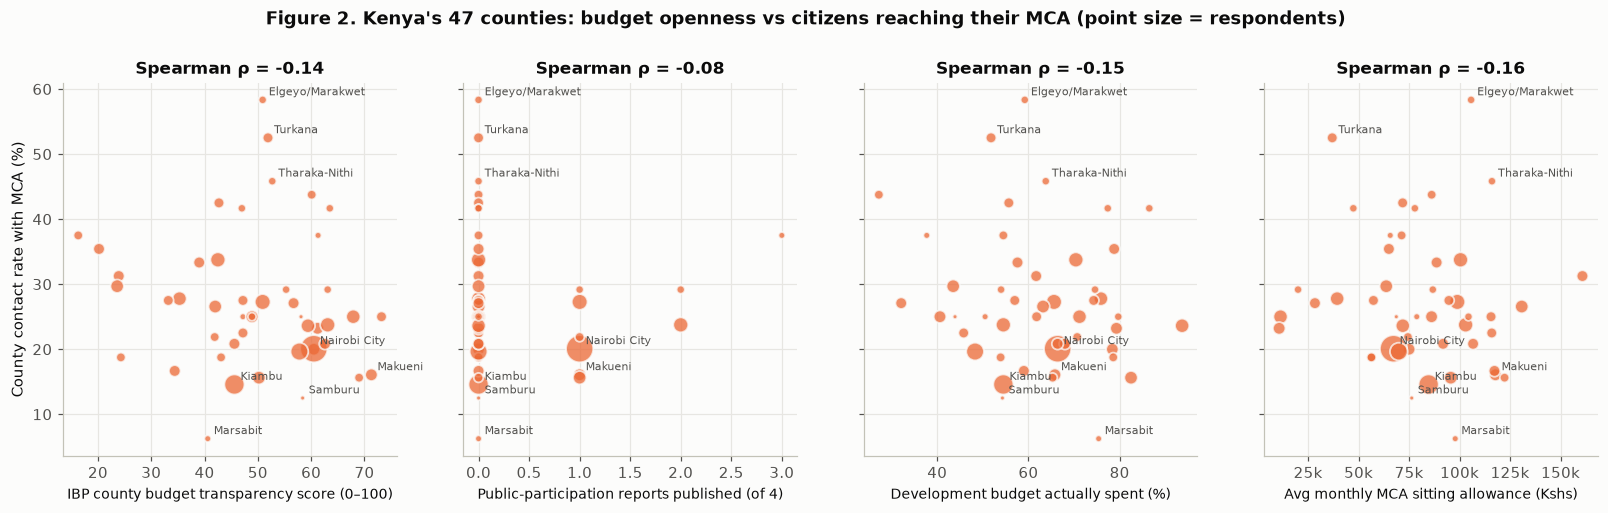

Spearman correlation of each county indicator with the county contact rate (47 counties):
cob_mcas                    -0.28
cbts_citizens_budget        -0.26
cob_mca_sitting_allowance   -0.16
cbts_docs_published         -0.15
cob_dev_absorption_pct      -0.15
cbts_transparency_score     -0.14
cob_pending_bills_pct       -0.14
cbts_pp_reports             -0.08
cob_total_absorption_pct    -0.07
cob_dev_budget_share_pct    -0.03
cob_osr_target_met_pct       0.21


In [8]:
COUNTY_SHOW = [("cbts_transparency_score", "IBP county budget transparency score (0–100)"),
               ("cbts_pp_reports", "Public-participation reports published (of 4)"),
               ("cob_dev_absorption_pct", "Development budget actually spent (%)"),
               ("cob_mca_sitting_allowance", "Avg monthly MCA sitting allowance (Kshs)")]
cty_k = (ken.groupby("region").agg(n=("contacted", "size"), contact_rate=("contacted", "mean"),
                                   **{c: (c, "first") for c, _ in COUNTY_SHOW}))
label_these = set(cty_k.nlargest(3, "contact_rate").index) | set(cty_k.nsmallest(3, "contact_rate").index) | {"Makueni", "Nairobi City"}

fig, axes = plt.subplots(1, 4, figsize=(18, 4.4), sharey=True)
for ax, (col, xlabel) in zip(axes, COUNTY_SHOW):
    ax.scatter(cty_k[col], cty_k["contact_rate"] * 100, s=cty_k["n"] * 1.2, color=ORANGE, alpha=0.75,
               edgecolor="#fcfcfb", linewidth=1.2)
    for name, r in cty_k.loc[cty_k.index.isin(label_these)].iterrows():
        ax.annotate(name, (r[col], r["contact_rate"] * 100), xytext=(4, 3), textcoords="offset points", fontsize=7, color=GREY_TEXT)
    rho = cty_k[[col, "contact_rate"]].corr(method="spearman").iloc[0, 1]
    ax.set_xlabel(xlabel, fontsize=9)
    ax.set_title(f"Spearman ρ = {rho:.2f}")
axes[3].xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v / 1000:.0f}k"))
axes[0].set_ylabel("County contact rate with MCA (%)")
fig.suptitle("Figure 2. Kenya's 47 counties: budget openness vs citizens reaching their MCA (point size = respondents)",
             y=1.03, fontweight="bold")
savefig("fig02_kenya_county_budget_vs_contact")
plt.show()

rhos = (cty_k.assign(**{c: ken.groupby("region")[c].first() for c in COUNTY_COLS})[COUNTY_COLS + ["contact_rate"]]
        .corr(method="spearman")["contact_rate"].drop("contact_rate").sort_values())
print("Spearman correlation of each county indicator with the county contact rate (47 counties):")
print(rhos.round(2).to_string())

> **Reading the output:** This is a striking Kenyan result. **None of the county budget indicators predicts higher MCA contact.** Most correlations are weakly *negative*: more transparent counties (ρ = −0.14), counties publishing a Citizens Budget (−0.26) and counties with more MCAs (−0.28) have slightly *fewer* citizens reaching their MCA. **Makueni**, nationally praised for participatory budgeting and among the most transparent counties (71/100), has one of the lowest contact rates (16%). The most engaged counties, **Elgeyo-Marakwet (58%) and Turkana (52%)**, are rural counties with middling transparency. The only positive sign is own-source revenue collection (ρ = 0.21).

There are two ways to read this. (1) **Publishing documents online is not the same as reaching citizens.** The CBTS measures what is on a county website, which most rural citizens never see. That fits the "box-ticking" participation in the problem statement. (2) **Small samples:** with 8–264 respondents per county, observed rates are noisy, so correlations near ±0.15 could be chance. The county data is unlikely to add much predictive power, but Experiment 2 will test that properly.

📘 **Concept: placing Kenya in context.** One more zoom-out, to the **country** level. Each point is a country: its average contact rate against its national IBP *public participation* score and internet penetration. This shows where Kenya sits among the countries the model will learn from.

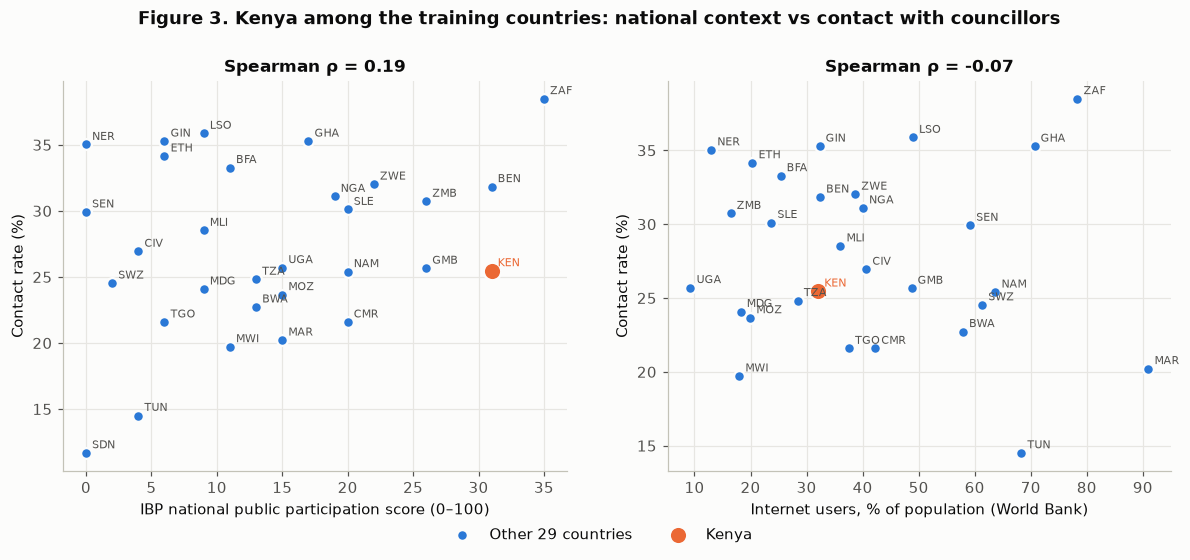

In [9]:
cty = df.groupby(["country", "iso3"]).agg(contact_rate=("contacted", "mean"),
                                          ibp_participation=("ibp_participation", "first"),
                                          internet=("wb_internet_users_pct", "first")).reset_index()

fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))
for ax, xcol, xlabel in [(axes[0], "ibp_participation", "IBP national public participation score (0–100)"),
                         (axes[1], "internet", "Internet users, % of population (World Bank)")]:
    other = cty[cty.iso3 != "KEN"]
    ax.scatter(other[xcol], other["contact_rate"] * 100, s=50, color=BLUE, edgecolor="#fcfcfb", linewidth=1.5, label=OTHERS)
    k = cty[cty.iso3 == "KEN"]
    ax.scatter(k[xcol], k["contact_rate"] * 100, s=130, color=ORANGE, edgecolor="#fcfcfb", linewidth=1.5, label="Kenya", zorder=3)
    for _, r in cty.iterrows():
        ax.annotate(r["iso3"], (r[xcol], r["contact_rate"] * 100), xytext=(4, 3), textcoords="offset points",
                    fontsize=7, color=ORANGE if r["iso3"] == "KEN" else GREY_TEXT)
    rho = cty[[xcol, "contact_rate"]].corr(method="spearman").iloc[0, 1]
    ax.set_xlabel(xlabel); ax.set_ylabel("Contact rate (%)")
    ax.set_title(f"Spearman ρ = {rho:.2f}")
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, frameon=False, loc="lower center", ncol=2, bbox_to_anchor=(0.5, -0.06))
fig.suptitle("Figure 3. Kenya among the training countries: national context vs contact with councillors", y=1.02, fontweight="bold")
savefig("fig03_kenya_in_african_context")
plt.show()

> **Reading the output:** At the country level, the national IBP participation score has a **weak positive** association with contact (ρ = 0.19), and internet penetration has **none** (ρ = −0.07). **Kenya is the striking case.** It has one of the best formal participation scores in the sample (31, alongside Benin and behind only South Africa), yet only an average contact rate (25.5%). Together with Figure 2 this tells a consistent story: **strong participation rules on paper, at national and county level, are not translating into more citizens reaching their MCA.** With only 30 countries, these correlations are imprecise; they motivate the merge but prove nothing on their own.

## 6. Feature engineering

📘 **Concept: turning raw survey items into meaningful signals.** Raw items are noisy. One question about going without food tells you a little; the **average across five deprivation questions** (food, water, medicine, fuel, cash) is Afrobarometer's established **Lived Poverty Index**, and it is far more stable. We build indices that map onto the barriers in the problem statement:

| Engineered feature | Built from | Barrier it measures |
|---|---|---|
| `service_proximity_index` | count of facilities within walking distance (post office, police, clinic, **govt office**, bank, market, school, transport) | **Physical distance** to government |
| `infrastructure_index` | electricity grid, piped water, sewage, mobile signal in the area | Remoteness / under-service |
| `digital_access_index` | internet use frequency, internet news, social-media news, phone with internet | **Cost of data / digital exclusion** |
| `interview_in_legal_language` | interview held in the language laws and budgets are written in (English in Kenya; French/Portuguese elsewhere) | **Legal-English barrier**. Swahili is an official language of Kenya, but county budgets and bills are published in English |
| `lived_poverty_index` | 5 deprivation items | Economic exclusion |
| `asset_index`, `traditional_media_index` | ownership & radio/TV/newspaper use | Resources & information access |
| `log_gdp_pc` | World Bank GDP per capita | Log-transform tames a skewed variable |

**County budget features** (`cbts_*`, `cob_*`) are converted to **county z-scores**: for each indicator we subtract the mean of the 47 counties and divide by their standard deviation, so 0 = an average Kenyan county and +1 = one standard deviation above it. Each county counts once, whether Afrobarometer interviewed 8 or 264 people there. Respondents outside Kenya have no county, so they get **0 ("average county")** plus a single `is_kenya` flag that tells the model which rows the county data really applies to. Section 7 explains why this matters.

**Why log GDP?** GDP per capita in our sample ranges from about \$1,000 to \$15,000+. A log scale treats a doubling from \$1k→\$2k the same as \$5k→\$10k, which matches how income affects people.

In [10]:
FACILITIES = ["ea_post_office", "ea_school", "ea_police_station", "ea_health_clinic", "ea_market",
              "ea_bank", "ea_govt_office", "ea_paid_transport"]
SERVICES = ["ea_electricity_grid", "ea_piped_water", "ea_sewage", "ea_mobile_service"]

df["service_proximity_index"] = df[FACILITIES].sum(axis=1, min_count=5)
df["infrastructure_index"] = df[SERVICES].sum(axis=1, min_count=3)
df["digital_access_index"] = pd.concat([df["freq_internet_use"] / 4, df["news_internet"] / 4,
                                        df["news_social_media"] / 4, df["phone_has_internet"]], axis=1).mean(axis=1)
df["traditional_media_index"] = df[["news_radio", "news_tv", "news_newspaper"]].mean(axis=1) / 4
df["lived_poverty_index"] = df[POVERTY].mean(axis=1)
df["asset_index"] = (df[OWN] > 0).where(df[OWN].notna()).mean(axis=1)
df["owns_phone_personally"] = (df["own_mobile_phone"] == 2).astype(float).where(df["own_mobile_phone"].notna())
df["interview_in_legal_language"] = df["interview_language"].isin([1, 2, 3]).astype(int)   # English/French/Portuguese
df["is_woman"] = (df["gender"] == 2).astype(int)
df["log_gdp_pc"] = np.log(df["wb_gdp_pc_ppp"])

# County z-scores across the 47 counties (one value per county, so each county counts once).
# Non-Kenyans get 0 = "average county"; the is_kenya flag marks where county data is real.
per_county = df.loc[df.is_kenya].groupby("region")[COUNTY_COLS].first()
COUNTY_Z = [f"{c}_z" for c in COUNTY_COLS]
df[COUNTY_Z] = ((df[COUNTY_COLS] - per_county.mean()) / per_county.std()).fillna(0).values
df["is_kenya_flag"] = df["is_kenya"].astype(int)

eng = ["service_proximity_index", "infrastructure_index", "digital_access_index", "traditional_media_index",
       "lived_poverty_index", "asset_index", "interview_in_legal_language"]
ken = df[df.is_kenya]
ken[eng + ["contacted"]].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
service_proximity_index,2399.0,5.31,2.03,0.0,4.00,6.00,7.00,8.0
infrastructure_index,2399.0,2.39,1.05,0.0,2.00,2.00,3.00,4.0
digital_access_index,2398.0,0.48,0.44,0.0,0.00,0.50,1.00,1.0
traditional_media_index,2399.0,0.56,0.24,0.0,0.33,0.58,0.67,1.0
lived_poverty_index,2399.0,1.40,0.87,0.0,0.80,1.20,2.00,4.0
interview_in_legal_language,2399.0,0.25,0.43,0.0,0.00,0.00,0.00,1.0
contacted,2399.0,0.25,0.44,0.0,0.00,0.00,1.00,1.0


📘 **Concept: correlation heatmap for redundancy and signal.** We compute it on **Kenyan respondents only**, including the county budget features. Two things to look for:
1. **Row `contacted`**: which features move with the target (signal)?
2. **Pairs of features that correlate strongly with each other**, e.g. digital access with education. Highly correlated (collinear) features make Logistic Regression coefficients unstable and split importance between them in Random Forests.

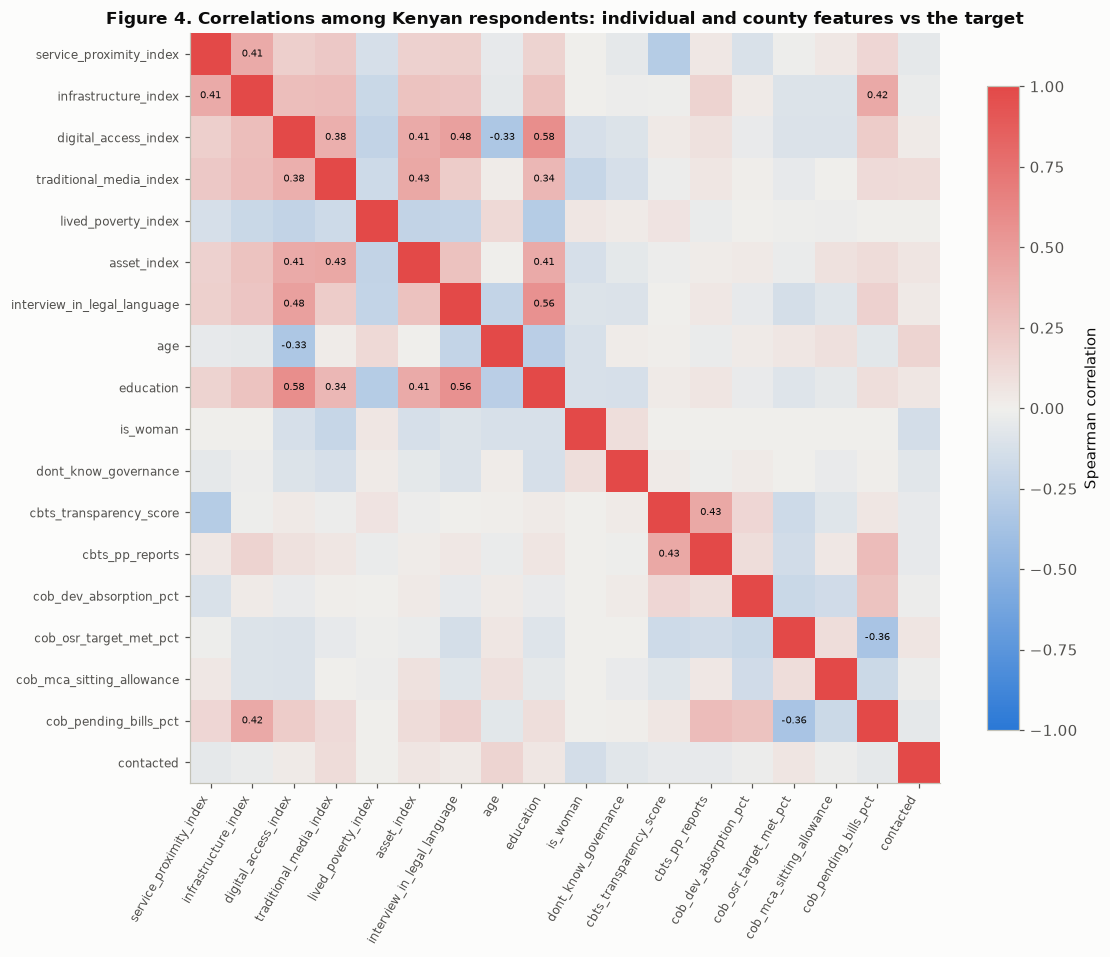

Strongest correlations with `contacted` (Kenya):
age                        0.160
is_woman                  -0.148
traditional_media_index    0.111
dont_know_governance      -0.078
asset_index                0.060
cob_osr_target_met_pct     0.055


In [11]:
corr_cols = eng + ["age", "education", "is_woman", "dont_know_governance", "cbts_transparency_score",
                   "cbts_pp_reports", "cob_dev_absorption_pct", "cob_osr_target_met_pct",
                   "cob_mca_sitting_allowance", "cob_pending_bills_pct", "contacted"]
corr = ken[corr_cols].corr(method="spearman")

fig, ax = plt.subplots(figsize=(11, 9.5))
im = ax.imshow(corr, cmap=DIVERGING, vmin=-1, vmax=1)
ax.set_xticks(range(len(corr_cols)), corr_cols, rotation=60, ha="right", fontsize=8)
ax.set_yticks(range(len(corr_cols)), corr_cols, fontsize=8)
ax.grid(False)
for i in range(len(corr_cols)):
    for j in range(len(corr_cols)):
        if abs(corr.iloc[i, j]) >= 0.3 and i != j:
            ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=6.5)
fig.colorbar(im, ax=ax, shrink=0.8, label="Spearman correlation")
ax.set_title("Figure 4. Correlations among Kenyan respondents: individual and county features vs the target")
savefig("fig04_kenya_correlation_heatmap")
plt.show()
print("Strongest correlations with `contacted` (Kenya):")
print(corr["contacted"].drop("contacted").sort_values(key=abs, ascending=False).head(6).round(3).to_string())

> **Reading the output:** Two lessons. **(1) No single feature is strongly related to MCA contact.** The `contacted` row is pale everywhere. The strongest are **age (ρ = 0.16), being a woman (−0.15) and traditional media use (0.11)**. Every county budget feature sits below |0.06| at the individual level. Prediction must therefore come from *combinations* of weak signals, so a modest ROC-AUC (around 0.60–0.70) is the realistic expectation for Kenya. **(2) Several features are redundant:** digital access correlates with education (0.58) and with being interviewed in English (0.48); education with English interviews (0.56). In Kenya, **an English-language interview is largely a marker of education**, so the "legal-English barrier" and the education gap are hard to separate. Among county features, transparency goes with publishing participation reports (0.43), and counties that meet revenue targets have fewer pending bills (−0.36).

## 7. Feature groups, the Kenya-focused split, and preprocessing

📘 **Concept: feature groups as an experiment.** We define five nested feature sets. Comparing them answers four practical questions:
- **A. Raw barrier items:** the individual survey items, unengineered (about 40 columns).
- **B. Engineered barriers:** our indices + demographics (16 columns). *Does feature engineering help, or at least compress the information without losing it?*
- **C. B + country context (IBP + World Bank):** *Does knowing which country someone lives in, and how open its budget is, add value?*
- **D. C + Kenyan county budget data (IBP county survey + Controller of Budget):** *Does the budget openness and performance of a citizen's county help predict whether they reach their MCA?* This is the Kenya-specific merge.
- **E. D + civic attitudes** (trust, perceived responsiveness…): *How much do attitudes add?* ⚠️ Attitudes may be **consequences** of contacting an MCA (reverse causality), and you would not know them for a citizen you are trying to reach. We treat E as an **upper bound**, not the deployable model.

We deliberately **exclude** other participation behaviours (attending community meetings, contacting an MP, protesting). They are so close to the target that they would leak it: a model would just learn "people who participate, participate".

In [12]:
DEMOGRAPHICS = ["age", "education", "is_woman", "employment"]
RAW_BARRIERS = (FACILITIES + SERVICES + ["ea_road_tarred"] + POVERTY + NEWS + OWN +
                ["phone_has_internet", "freq_mobile_use", "freq_internet_use", "home_electricity_connected",
                 "interview_in_legal_language"])
ENGINEERED = (["service_proximity_index", "infrastructure_index", "ea_govt_office", "ea_road_tarred",
               "digital_access_index", "freq_internet_use", "owns_phone_personally", "traditional_media_index",
               "lived_poverty_index", "asset_index", "home_electricity_connected", "interview_in_legal_language"])
COUNTRY = ["ibp_transparency", "ibp_participation", "ibp_oversight", "wb_internet_users_pct",
           "wb_mobile_subs_per100", "wb_rural_pop_pct", "log_gdp_pc"]
COUNTY = COUNTY_Z + ["is_kenya_flag"]   # already on a common scale (Section 6)
ATTITUDE_FEATS = ATTITUDES + ["dont_know_governance"]
CATEGORICAL = ["settlement", "interview_lang_group"]

FEATURE_SETS = {
    "A. Raw items": dict(num=RAW_BARRIERS + DEMOGRAPHICS, cat=CATEGORICAL),
    "B. Engineered": dict(num=ENGINEERED + DEMOGRAPHICS, cat=CATEGORICAL),
    "C. B + country context": dict(num=ENGINEERED + DEMOGRAPHICS + COUNTRY, cat=CATEGORICAL),
    "D. C + county budget data": dict(num=ENGINEERED + DEMOGRAPHICS + COUNTRY + COUNTY, cat=CATEGORICAL),
    "E. D + attitudes": dict(num=ENGINEERED + DEMOGRAPHICS + COUNTRY + COUNTY + ATTITUDE_FEATS, cat=CATEGORICAL),
}
for k, v in FEATURE_SETS.items():
    print(f"{k:28s} {len(v['num']) + len(v['cat']):3d} input columns")
print("\nCounty budget features (county z-scores):", COUNTY)

A. Raw items                  40 input columns
B. Engineered                 18 input columns
C. B + country context        25 input columns
D. C + county budget data     37 input columns
E. D + attitudes              45 input columns

County budget features (county z-scores): ['cbts_docs_published_z', 'cbts_pp_reports_z', 'cbts_citizens_budget_z', 'cbts_transparency_score_z', 'cob_dev_absorption_pct_z', 'cob_total_absorption_pct_z', 'cob_dev_budget_share_pct_z', 'cob_osr_target_met_pct_z', 'cob_mca_sitting_allowance_z', 'cob_mcas_z', 'cob_pending_bills_pct_z', 'is_kenya_flag']


📘 **Concept: a three-way split designed around Kenya.**
- **Training set** is what models learn from. It contains **non-Kenyan respondents plus 60% of Kenyans**.
- **Validation set** is used to *choose* between models, thresholds and DL architectures.
- **Test set** is touched **once**, at the very end. If you tune on the test set, your reported score is optimistic, because you have indirectly fitted to it.

Because **Kenya is what we evaluate on**, we hold out a larger share of Kenyans (20% validation + 20% test = 480 each) than of other countries (15% + 15%). With only 15% of 2,399 Kenyans (about 360) in the test set, every score would be very noisy.

We **stratify** on the target, separately for each country. Every split then keeps the same contact rate and the same country mix.

In [13]:
from sklearn.model_selection import train_test_split

def three_way(frame, val_share, test_share):
    strata = frame["iso3"] + "_" + frame["contacted"].astype(str)
    train, temp = train_test_split(frame, test_size=val_share + test_share, stratify=strata, random_state=SEED)
    val, test = train_test_split(temp, test_size=test_share / (val_share + test_share),
                                 stratify=strata.loc[temp.index], random_state=SEED)
    return train, val, test

ken_parts = three_way(df[df.is_kenya], 0.20, 0.20)
other_parts = three_way(df[~df.is_kenya], 0.15, 0.15)
train_df, val_df, test_df = (pd.concat([o, k]).reset_index(drop=True) for o, k in zip(other_parts, ken_parts))
y_train, y_val, y_test = train_df["contacted"].values, val_df["contacted"].values, test_df["contacted"].values
KEN_VAL, KEN_TEST = val_df["is_kenya"].values, test_df["is_kenya"].values   # boolean masks for Kenyan rows

for name, part in [("train", train_df), ("validation", val_df), ("test", test_df)]:
    k = part[part.is_kenya]
    print(f"{name:10s} {len(part):6,} rows | Kenyans {len(k):5,} (contact rate {k.contacted.mean():.3f}) | "
          f"others {len(part) - len(k):6,}")

train      29,530 rows | Kenyans 1,439 (contact rate 0.254) | others 28,091
validation  6,500 rows | Kenyans   480 (contact rate 0.254) | others  6,020
test        6,500 rows | Kenyans   480 (contact rate 0.256) | others  6,020


📘 **Concept: cross-validation that scores only Kenyans.** Ordinary k-fold CV scores every country, so a model could look good overall and still be poor for Kenya. We build our own CV folds:
1. Split the **Kenyan training rows** into 5 stratified folds.
2. For each fold: **train** on all non-Kenyan rows + the other 4 Kenyan folds; **score** on the held-out Kenyan fold only.

The `train_on` argument also lets us train on *Kenyans only* or *Africa only*. That is how Experiment 1 tests whether borrowing data from other countries helps. Each Kenyan fold holds only about 290 people, so we **repeat** the 5-fold split 3 times with different shuffles (15 scores) and report the mean ± standard deviation.

Scikit-Learn accepts a list of `(train_indices, test_indices)` pairs anywhere it takes `cv=`, so these folds plug straight into `cross_validate`, `RandomizedSearchCV`, `validation_curve` and `learning_curve`.

In [14]:
from sklearn.model_selection import RepeatedStratifiedKFold

def kenya_folds(frame, train_on="africa + kenya", n_splits=5, n_repeats=1):
    """(train_positions, test_positions) pairs. Test folds contain ONLY Kenyan respondents."""
    ken_pos = np.flatnonzero(frame["is_kenya"].values)
    other_pos = np.flatnonzero(~frame["is_kenya"].values)
    splitter = RepeatedStratifiedKFold(n_splits=n_splits, n_repeats=n_repeats, random_state=SEED)
    folds = []
    for k_tr, k_te in splitter.split(ken_pos, frame["contacted"].values[ken_pos]):
        train = {"kenya only": ken_pos[k_tr],
                 "africa only": other_pos,
                 "africa + kenya": np.concatenate([other_pos, ken_pos[k_tr]])}[train_on]
        folds.append((train, ken_pos[k_te]))
    return folds

KCV = kenya_folds(train_df)                  # 5 folds: tuning and diagnostics
KCV15 = kenya_folds(train_df, n_repeats=3)   # 15 folds: the main experiments
tr, te = KCV[0]
print(f"Fold 1: train on {len(tr):,} rows ({train_df.is_kenya.values[tr].sum():,} Kenyans), "
      f"score on {len(te)} Kenyans (all Kenyan: {train_df.is_kenya.values[te].all()})")

Fold 1: train on 29,242 rows (1,151 Kenyans), score on 288 Kenyans (all Kenyan: True)


📘 **Concept: preprocessing pipelines prevent data leakage.** Imputation medians and scaling means must be computed **only from the training data**. If you compute them on the full dataset, information from the test set leaks into training.

Scikit-Learn's `Pipeline` + `ColumnTransformer` handle this. When you call `.fit()` on the training set, every step learns from the training data only. When you call `.predict()` on new data, the same learned transformations are applied. Our steps:
- **Numeric:** median imputation **+ a missing-indicator column** (so "this value is missing" can itself be a signal), then standard scaling (mean 0, sd 1). Scaling matters for Logistic Regression, SVMs and neural networks, not for trees.
- **Categorical:** one-hot encoding. `handle_unknown="ignore"` means an unseen category at prediction time becomes all-zeros instead of crashing.

**The county columns are passed through unscaled.** They were already standardised across the 47 counties in Section 6, and non-Kenyans hold 0. Scaling them *again* over all rows would be a mistake worth understanding. A column that is 0 for 95% of rows has a tiny overall standard deviation (about 0.22), so `StandardScaler` would multiply every Kenyan's county values by about 4.5. In an earlier version of this notebook, that silently broke the RBF-kernel SVM. Its distances between Kenyans became dominated by the 11 inflated county columns, the kernel between any two Kenyans from different counties shrank towards zero, and it scored 0.53 ROC-AUC on Kenyans while scoring 0.67 elsewhere. **Lesson: always ask what scaling does to a feature that only exists for a subset of rows.**

In [15]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

def make_preprocessor(num, cat):
    numeric = Pipeline([("impute", SimpleImputer(strategy="median", add_indicator=True)),
                        ("scale", StandardScaler())])
    categorical = Pipeline([("impute", SimpleImputer(strategy="most_frequent")),
                            ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))])
    county = [c for c in num if c in COUNTY]          # pre-standardised, complete: pass through as-is
    return ColumnTransformer([("num", numeric, [c for c in num if c not in COUNTY]),
                              ("county", "passthrough", county),
                              ("cat", categorical, cat)],
                             verbose_feature_names_out=False)

def cols(fs):
    return FEATURE_SETS[fs]["num"] + FEATURE_SETS[fs]["cat"]

demo = make_preprocessor(**FEATURE_SETS["D. C + county budget data"]).fit(train_df[cols("D. C + county budget data")])
names = demo.get_feature_names_out()
print(f"{len(cols('D. C + county budget data'))} input columns -> {len(names)} model features after imputation indicators + one-hot")
print([n for n in names if "cbts_transparency" in n or "kenya" in n or "lang_group" in n])
Xd = demo.transform(train_df[cols("D. C + county budget data")])
z = list(names).index("cbts_transparency_score_z")
print(f"cbts_transparency_score_z after preprocessing: Kenyans sd = {Xd[train_df.is_kenya.values, z].std():.2f}, "
      f"others all = {np.unique(Xd[~train_df.is_kenya.values, z])}")

37 input columns -> 57 model features after imputation indicators + one-hot
['cbts_transparency_score_z', 'is_kenya_flag', 'interview_lang_group_Arabic', 'interview_lang_group_English', 'interview_lang_group_French', 'interview_lang_group_Local language', 'interview_lang_group_Portuguese', 'interview_lang_group_Swahili']


cbts_transparency_score_z after preprocessing: Kenyans sd = 0.95, others all = [0.]


## 8. Baselines: what does "good" look like for Kenya?

📘 **Concept: the accuracy paradox.** When only about a quarter of Kenyans contacted their MCA, a "model" that always predicts **"did not contact"** scores high accuracy while being useless. That is why we report:
- **ROC-AUC:** the probability that a randomly chosen contacter gets a higher score than a randomly chosen non-contacter. 0.5 = coin flip, 1.0 = perfect. It is threshold-free.
- **PR-AUC (average precision):** focuses on the minority class. Its baseline equals the positive rate, not 0.5, so it is a harsher and more honest metric under imbalance.
- **Balanced accuracy** and **F1** at a decision threshold.

Dummy classifiers give us the floor every real model must beat. From here on, **every score is computed on Kenyan respondents** unless stated otherwise.

In [16]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, f1_score, roc_auc_score,
                             average_precision_score, precision_score, recall_score)

yk_val = y_val[KEN_VAL]
for strategy in ["most_frequent", "stratified"]:
    dummy = DummyClassifier(strategy=strategy, random_state=SEED).fit(train_df[["age"]], y_train)
    Xk = val_df.loc[KEN_VAL, ["age"]]
    p, s = dummy.predict(Xk), dummy.predict_proba(Xk)[:, 1]
    print(f"{strategy:14s} accuracy={accuracy_score(yk_val, p):.3f}  balanced_acc={balanced_accuracy_score(yk_val, p):.3f}  "
          f"F1={f1_score(yk_val, p, zero_division=0):.3f}  ROC-AUC={roc_auc_score(yk_val, s):.3f}  "
          f"PR-AUC={average_precision_score(yk_val, s):.3f}")

most_frequent  accuracy=0.746  balanced_acc=0.500  F1=0.000  ROC-AUC=0.500  PR-AUC=0.254
stratified     accuracy=0.623  balanced_acc=0.523  F1=0.301  ROC-AUC=0.523  PR-AUC=0.264


> **Reading the output:** On the 480 Kenyan validation respondents, the "always predict *no contact*" model reaches **74.6% accuracy** while finding **zero** contacters (F1 = 0). This is the accuracy paradox, and it is why accuracy alone is never reported for this project. Both dummies sit at ROC-AUC ≈ 0.50 and PR-AUC ≈ 0.25 (the Kenyan positive rate). Those are the floors to beat.

## 9. Experiment 1: should a Kenya model learn from other countries?

📘 **Concept: transfer and "borrowing strength".** This experiment justifies the whole design. We train the same two models on three different sources and score them **on the same held-out Kenyans**:
1. **Kenya only:** about 1,150 Kenyans per training fold. Pure, but small.
2. **Africa only:** about 32,000 non-Kenyans, and **not a single Kenyan**. Large, but could the patterns differ in Kenya?
3. **Africa + Kenya:** both.

If (3) beats (1), the extra countries are teaching the model something true about Kenya. We use feature set C (individual + country context), which every source can use. The county budget data exists only for Kenyans, so an "Africa only" model could not learn from it; it is tested separately in Experiment 2.

📘 **Concept: why two algorithms?** Logistic Regression is simple (high bias, low variance), so it can cope with small data. Gradient Boosting is flexible (low bias, higher variance), so it needs more data. Data size should matter more for the flexible model.

In [17]:
from sklearn.model_selection import cross_validate
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from functools import partial

# HistGradientBoosting silently turns early stopping ON only when n_samples > 10,000.
# We switch it on explicitly so the model behaves the same at every data size
# (otherwise learning curves show a confusing jump at 10k rows, and Kenya-only models differ).
HGB = partial(HistGradientBoostingClassifier, early_stopping=True, validation_fraction=0.1, n_iter_no_change=20)
SCORING = {"roc_auc": "roc_auc", "pr_auc": "average_precision", "f1": "f1", "bal_acc": "balanced_accuracy"}
MODELS_EXP = {"LogReg": lambda: LogisticRegression(max_iter=3000, class_weight="balanced"),
              "GradBoost": lambda: HGB(class_weight="balanced", random_state=SEED)}

def kenya_cv(fs, model, cv):
    pipe = Pipeline([("prep", make_preprocessor(**FEATURE_SETS[fs])), ("model", model)])
    return cross_validate(pipe, train_df[cols(fs)], y_train, cv=cv, scoring=SCORING, n_jobs=-1, return_train_score=True)

rows, source_folds = [], {}
for source in ["kenya only", "africa only", "africa + kenya"]:
    folds = kenya_folds(train_df, train_on=source, n_repeats=3)
    for mname, make in MODELS_EXP.items():
        cv = kenya_cv("C. B + country context", make(), folds)
        source_folds[(source, mname)] = cv["test_roc_auc"]
        rows.append({"trained on": source, "model": mname, "training rows": len(folds[0][0]),
                     "Kenya ROC-AUC": cv["test_roc_auc"].mean(), "± sd": cv["test_roc_auc"].std(),
                     "Kenya PR-AUC": cv["test_pr_auc"].mean(), "± sd ": cv["test_pr_auc"].std()})
source_results = pd.DataFrame(rows).round(3)
source_results.to_csv(RESULTS_DIR / "exp1_training_source.csv", index=False)
source_results

,trained on,model,training rows,Kenya ROC-AUC,± sd,Kenya PR-AUC,± sd
0,kenya only,LogReg,1151,0.626,0.033,0.345,0.037
1,kenya only,GradBoost,1151,0.616,0.030,0.356,0.032
2,africa only,LogReg,28091,0.626,0.038,0.346,0.034
3,africa only,GradBoost,28091,0.623,0.037,0.354,0.038
4,africa + kenya,LogReg,29242,0.627,0.038,0.346,0.035
5,africa + kenya,GradBoost,29242,0.635,0.036,0.374,0.034


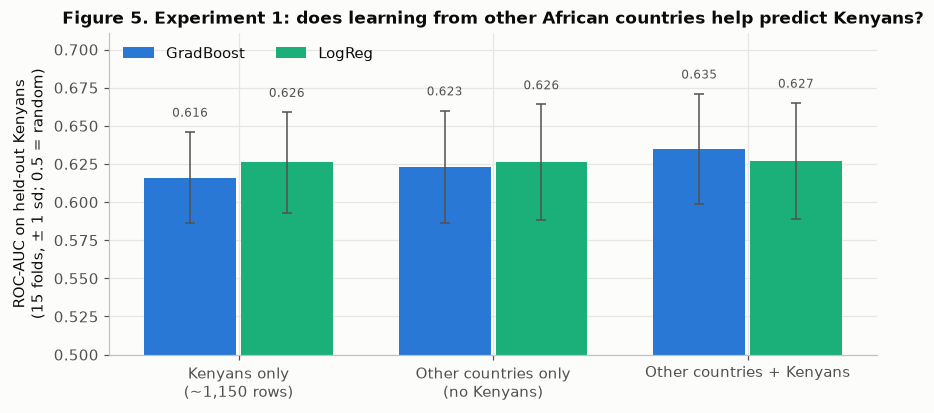

In [18]:
fig, ax = plt.subplots(figsize=(9, 3.8))
pivot = source_results.pivot(index="trained on", columns="model", values="Kenya ROC-AUC").loc[["kenya only", "africa only", "africa + kenya"]]
err = source_results.pivot(index="trained on", columns="model", values="± sd").loc[pivot.index]
x, w = np.arange(len(pivot)), 0.36
for i, (m, color) in enumerate(zip(pivot.columns, [BLUE, AQUA])):
    bars = ax.bar(x + (i - 0.5) * (w + 0.02), pivot[m], width=w, color=color, label=m,
                  yerr=err[m], error_kw=dict(ecolor=GREY_TEXT, lw=1, capsize=3))
    ax.bar_label(bars, fmt="%.3f", fontsize=8, color=GREY_TEXT, padding=8)
ax.set_xticks(x, ["Kenyans only\n(~1,150 rows)", "Other countries only\n(no Kenyans)", "Other countries + Kenyans"])
ax.set_ylim(0.5, (pivot + err).values.max() + 0.04)
ax.set_ylabel("ROC-AUC on held-out Kenyans\n(15 folds, ± 1 sd; 0.5 = random)")
ax.legend(frameon=False, ncol=2, loc="upper left")
ax.set_title("Figure 5. Experiment 1: does learning from other African countries help predict Kenyans?")
savefig("fig05_exp1_training_source")
plt.show()

📘 **Concept: paired comparison.** The ± sd bars above overlap, but they mix two kinds of noise: *which model is better* and *how hard each fold happens to be*. Some groups of 288 Kenyans are simply harder to predict than others, for every model. Because every training source was scored on **exactly the same 15 Kenyan folds**, we can compare them **fold by fold**: compute the difference in each fold, then look at the mean difference and how many of the 15 folds it wins. Fold difficulty cancels out. This is the same idea as a paired t-test, and it is far more sensitive than comparing two averages.

In [19]:
def paired(a, b):
    d = a - b
    return {"mean difference": d.mean(), "sd of difference": d.std(), "folds improved (of 15)": int((d > 0).sum())}

pairs = {f"{m}: africa + kenya vs kenya only": paired(source_folds[("africa + kenya", m)], source_folds[("kenya only", m)])
         for m in MODELS_EXP}
pairs.update({f"{m}: africa only vs kenya only": paired(source_folds[("africa only", m)], source_folds[("kenya only", m)])
              for m in MODELS_EXP})
pd.DataFrame(pairs).T.round(3)

,mean difference,sd of difference,folds improved (of 15)
LogReg: africa + kenya vs kenya only,0.001,0.018,6.0
GradBoost: africa + kenya vs kenya only,0.020,0.035,11.0
LogReg: africa only vs kenya only,-0.000,0.018,6.0
GradBoost: africa only vs kenya only,0.007,0.031,8.0


> **Reading the output:** This experiment answers the question *"why use other countries?"*.
- **Gradient Boosting benefits from borrowing.** Trained on Kenyans only it reaches 0.616 ROC-AUC (PR-AUC 0.356). Adding the other countries raises this to **0.635 (PR-AUC 0.374)**, and the paired comparison shows the gain in **11 of 15 Kenyan folds**. A flexible model needs more data than 1,150 Kenyans can give it.
- **A model that has never seen a Kenyan does as well as one trained only on Kenyans** (0.623 vs 0.616; 8 of 15 folds). The patterns of who reaches a local representative (age, gender, resources, media) are **largely shared across African countries**.
- **Logistic Regression does not care** (0.626–0.627 whatever it trains on). It is a high-bias model: a linear rule can be learned well from 1,150 rows, so more data adds nothing.

So the design choice is justified, though the gain is modest. Note the large ± sd bars: with about 290 Kenyans per fold, scores vary by ±0.035 from fold to fold. **That is exactly why the paired comparison is needed.** Comparing averages alone would have called all six bars "the same".

## 10. Experiment 2: does feature engineering, and the county budget merge, help?

📘 **Concept: k-fold cross-validation and noise.** One train/validation split gives one noisy number. Our 15 Kenya-scored folds give a **mean ± standard deviation**. If two feature sets differ by less than about one standard deviation, the difference is probably noise.

Every model here trains on **Africa + Kenya** (the winner of Experiment 1 is checked in the output) and is scored on Kenyans. We run two very different learners on each feature set. A feature set that helps *both* is more convincing than one that helps only one.

In [20]:
rows, fs_folds = [], {}
for fs in FEATURE_SETS:
    for mname, make in MODELS_EXP.items():
        cv = kenya_cv(fs, make(), KCV15)
        fs_folds[(fs, mname)] = cv["test_roc_auc"]
        rows.append({"feature_set": fs, "model": mname, "n_inputs": len(cols(fs)),
                     "Kenya ROC-AUC": f"{cv['test_roc_auc'].mean():.3f} ± {cv['test_roc_auc'].std():.3f}",
                     "Kenya PR-AUC": f"{cv['test_pr_auc'].mean():.3f} ± {cv['test_pr_auc'].std():.3f}",
                     "_roc": cv["test_roc_auc"].mean(), "_sd": cv["test_roc_auc"].std(), "_pr": cv["test_pr_auc"].mean()})
fs_results = pd.DataFrame(rows)
fs_results.drop(columns=["_roc", "_sd", "_pr"]).to_csv(RESULTS_DIR / "exp2_feature_sets.csv", index=False)
fs_results.drop(columns=["_roc", "_sd", "_pr"])

,feature_set,model,n_inputs,Kenya ROC-AUC,Kenya PR-AUC
0,A. Raw items,LogReg,40,0.629 ± 0.034,0.352 ± 0.034
1,A. Raw items,GradBoost,40,0.637 ± 0.037,0.366 ± 0.041
2,B. Engineered,LogReg,18,0.625 ± 0.038,0.347 ± 0.034
3,B. Engineered,GradBoost,18,0.627 ± 0.032,0.353 ± 0.031
4,C. B + country context,LogReg,25,0.627 ± 0.038,0.346 ± 0.035
5,C. B + country context,GradBoost,25,0.635 ± 0.036,0.374 ± 0.034
6,D. C + county budget data,LogReg,37,0.634 ± 0.024,0.363 ± 0.024
7,D. C + county budget data,GradBoost,37,0.621 ± 0.031,0.351 ± 0.025
8,E. D + attitudes,LogReg,45,0.723 ± 0.038,0.472 ± 0.056
9,E. D + attitudes,GradBoost,45,0.713 ± 0.031,0.467 ± 0.038


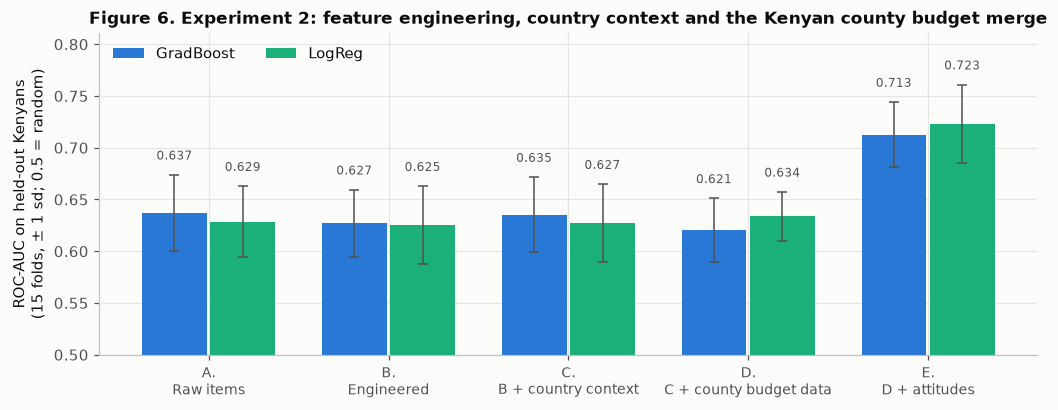

In [21]:
fig, ax = plt.subplots(figsize=(11, 3.8))
pivot = fs_results.pivot(index="feature_set", columns="model", values="_roc")
err = fs_results.pivot(index="feature_set", columns="model", values="_sd")
x, w = np.arange(len(pivot)), 0.36
for i, (m, color) in enumerate(zip(pivot.columns, [BLUE, AQUA])):
    bars = ax.bar(x + (i - 0.5) * (w + 0.02), pivot[m], width=w, color=color, label=m,
                  yerr=err[m], error_kw=dict(ecolor=GREY_TEXT, lw=1, capsize=3))
    ax.bar_label(bars, fmt="%.3f", fontsize=8, color=GREY_TEXT, padding=8)
ax.set_xticks(x, [f.replace(". ", ".\n", 1) for f in pivot.index], fontsize=9)
ax.set_ylim(0.5, (pivot + err).values.max() + 0.05)
ax.set_ylabel("ROC-AUC on held-out Kenyans\n(15 folds, ± 1 sd; 0.5 = random)")
ax.legend(frameon=False, ncol=2, loc="upper left")
ax.set_title("Figure 6. Experiment 2: feature engineering, country context and the Kenyan county budget merge")
savefig("fig06_exp2_feature_sets")
plt.show()

📘 **Concept: paired comparison of feature sets.** As in Experiment 1, every feature set was scored on the same 15 Kenyan folds, so we compare each step **fold by fold**: does adding a block of features improve the score in most folds, or only on average?

In [22]:
names = list(FEATURE_SETS)
steps = {f"{m}: {b[:1]} vs {a[:1]}  ({b[3:]})": paired(fs_folds[(b, m)], fs_folds[(a, m)])
         for m in MODELS_EXP for a, b in zip(names, names[1:])}
paired_fs = pd.DataFrame(steps).T.round(3)
paired_fs.to_csv(RESULTS_DIR / "exp2_paired_comparisons.csv")
paired_fs

,mean difference,sd of difference,folds improved (of 15)
LogReg: B vs A (Engineered),-0.004,0.012,6.0
LogReg: C vs B (B + country context),0.002,0.003,12.0
LogReg: D vs C (C + county budget data),0.007,0.025,9.0
LogReg: E vs D (D + attitudes),0.089,0.032,15.0
GradBoost: B vs A (Engineered),-0.010,0.018,4.0
GradBoost: C vs B (B + country context),0.008,0.012,12.0
GradBoost: D vs C (C + county budget data),-0.015,0.031,5.0
GradBoost: E vs D (D + attitudes),0.092,0.025,15.0


> **Reading the output:** Reading the paired table step by step:
- **Feature engineering (A → B)** costs a little: about −0.01 ROC-AUC for Gradient Boosting, and the engineered set loses in 11 of 15 folds. Compressing 40 raw items into 18 indices throws away some detail, for example *which* facility is nearby. The indices remain far easier to explain, and each maps onto one barrier in the problem statement.
- **Country context (B → C)** helps **consistently but slightly**: it wins **12 of 15 folds for both models** (+0.002 for Logistic Regression, +0.008 for Gradient Boosting). Knowing the national context lets the model place Kenyans relative to the other countries it learns from.
- **County budget data (C → D)** gives **no reliable gain**. Logistic Regression improves slightly (+0.007, 9 of 15 folds); Gradient Boosting gets slightly worse (−0.015, only 5 of 15 folds). The 12 county columns take only **47 distinct combinations**, one per county, so a flexible tree model can use them to memorise "this county's respondents in my training folds" rather than learn a general rule. The linear model cannot memorise, so it is unaffected. This matches the EDA in Figure 2: county budget openness barely relates to whether citizens reach their MCA.
- **Attitudes (D → E)** produce a large jump (+0.09, all 15 folds) to about 0.71–0.72. As explained above, they partly measure the *consequences* of contact (someone who met their MCA knows more about the budget), so E is an upper bound, not a deployable model.

**Decision.** We carry **feature set D** (engineered barriers + country context + county budget data) forward as the main model. This is a judgement call, so here is the reasoning:
1. **Statistically, C and D are close to tied.** The mean differences (+0.007 and −0.015) are about half the fold-to-fold standard deviation of the difference (0.025–0.031), and the two models disagree on the direction. Pure parsimony (Occam's razor) would pick the smaller set, C, and Gradient Boosting's slight preference for C is a fair argument for it.
2. **D serves the Kenyan purpose.** A county government using this model needs it to respond to *county* conditions: if a county starts publishing participation reports, the model should be able to reflect that. D also makes the county analysis (Section 17) and the three-level neural network (Section 15.4) possible.
3. **The cost is small and uncertain,** and Experiment 6 (Section 17) tests county data on the question it is really for, predicting *unseen* counties, while Section 18 (permutation importance) will show whether the final model actually relies on the county features. If it doesn't, that is itself a finding.

We keep the engineered features (B-style) rather than raw items despite their small cost, because every engineered feature maps onto a barrier in the problem statement, which makes the explainability sections meaningful. **E (attitudes) stays in the report as an upper bound only.**

In [23]:
FS = "D. C + county budget data"
NUM_COLS, CAT_COLS = FEATURE_SETS[FS]["num"], FEATURE_SETS[FS]["cat"]
FEATURES = NUM_COLS + CAT_COLS
X_train, X_val, X_test = train_df[FEATURES], val_df[FEATURES], test_df[FEATURES]
print(f"Final feature set: {FS} ({len(FEATURES)} columns)")

Final feature set: D. C + county budget data (37 columns)


## 11. Experiment 3: comparing traditional ML algorithms

📘 **Concept: different algorithms, different assumptions.**
- **Logistic Regression** assumes the log-odds are a *linear* (additive) function of the features. Interpretable and a strong baseline.
- **Random Forest** builds many deep decision trees on bootstrapped samples and averages them (**bagging**), which reduces variance. It captures interactions such as "rural AND no internet".
- **Gradient Boosting (HistGradientBoosting)** builds shallow trees *sequentially*, each one correcting the previous errors (**boosting**), which reduces bias. It is usually the strongest on tabular data.
- **SVM (RBF kernel)** finds a maximum-margin boundary in a transformed space. Exact kernel SVMs cost O(n²) memory and time, which is too slow for about 33k rows, so we use the **Nyström approximation** of the RBF kernel followed by a linear SVM. This teaches a real engineering trade-off: an approximate method that scales vs an exact one that doesn't.

📘 **Concept: class imbalance handling.** `class_weight="balanced"` makes each mistake on the rare class cost more (weight ∝ 1/class frequency), so the model can't ignore contacters.

📘 **Concept: train vs CV score = overfitting check.** We also record the *training* score (on all training rows). A big gap (e.g. train AUC 0.95, Kenya CV 0.68) means the model memorises the training data.

In [24]:
from sklearn.kernel_approximation import Nystroem
from sklearn.svm import LinearSVC

candidates = {
    "Logistic Regression": LogisticRegression(max_iter=3000, class_weight="balanced"),
    "Random Forest": RandomForestClassifier(n_estimators=300, min_samples_leaf=5, class_weight="balanced_subsample",
                                            n_jobs=-1, random_state=SEED),
    "Gradient Boosting": HGB(class_weight="balanced", random_state=SEED),
    "SVM (RBF, Nyström)": make_pipeline(Nystroem(kernel="rbf", gamma=0.02, n_components=400, random_state=SEED),
                                        LinearSVC(C=0.1, class_weight="balanced", random_state=SEED)),
}

rows = []
for name, model in candidates.items():
    t0 = time.time()
    cv = kenya_cv(FS, model, KCV15)
    rows.append({"model": name,
                 "train ROC-AUC (all rows)": cv["train_roc_auc"].mean(),
                 "Kenya CV ROC-AUC": cv["test_roc_auc"].mean(), "± sd": cv["test_roc_auc"].std(),
                 "Kenya CV PR-AUC": cv["test_pr_auc"].mean(),
                 "Kenya CV F1": cv["test_f1"].mean(), "Kenya CV bal. acc": cv["test_bal_acc"].mean(),
                 "seconds": time.time() - t0})
algo_results = pd.DataFrame(rows).set_index("model").round(3)
algo_results.to_csv(RESULTS_DIR / "exp3_algorithms_cv.csv")
algo_results

,train ROC-AUC (all rows),Kenya CV ROC-AUC,± sd,Kenya CV PR-AUC,Kenya CV F1,Kenya CV bal. acc,seconds
model,,,,,,,
Logistic Regression,0.655,0.634,0.024,0.363,0.413,0.591,2.910
Random Forest,0.942,0.639,0.033,0.367,0.273,0.548,41.122
Gradient Boosting,0.775,0.621,0.031,0.351,0.382,0.575,8.054
"SVM (RBF, Nyström)",0.686,0.642,0.029,0.376,0.418,0.599,23.881


> **Reading the output:** All four algorithms land within 0.02 ROC-AUC of each other on Kenyans (0.621–0.642), well inside one fold standard deviation (about 0.03). This is another sign that **the information in the features, not the algorithm, is the limit.** The SVM, fixed by passing the county z-scores through unscaled (Section 7), now scores 0.642, the best untuned result. Look at the **train vs CV gap**: Random Forest scores 0.942 on the training rows but 0.639 on held-out Kenyans, so it **memorises** the training set (deep trees). Gradient Boosting has a smaller gap (0.775 vs 0.621). Logistic Regression has almost none (0.655 vs 0.634), the textbook sign of a **high-bias** model that is too simple to overfit. The Random Forest is also the slowest (about 42 s for 15 folds).

## 12. Experiment 4: hyperparameter tuning

📘 **Concept: hyperparameters vs parameters.** *Parameters* (tree splits, regression weights) are learned from data. *Hyperparameters* (learning rate, tree depth, regularisation strength) are chosen by **you** before training. Tuning searches for the hyperparameters that give the best **cross-validated** score, here on the Kenya-scored folds.

📘 **Concept: Randomized vs Grid search.** Grid search tries every combination: 5 values × 5 params = 3,125 fits. **Randomized search** samples, say, 25 combinations from distributions. Bergstra & Bengio (2012) showed it finds near-optimal settings far faster, because usually only a few hyperparameters really matter. We use `loguniform` for scale-type parameters (learning rate, regularisation), because 0.01→0.1 matters as much as 0.1→1.

We optimise **PR-AUC** (`average_precision`) because it is the metric most sensitive to how well we find the minority class.

For Logistic Regression we grid-search `C` (the *inverse* of regularisation strength: small C = strong penalty) and `l1_ratio` (0 = **L2/ridge**, which shrinks all weights a little; 1 = **L1/lasso**, which can push weights to exactly zero, i.e. built-in feature selection). We use the `saga` solver, the one that supports both penalties. You may see a few `ConvergenceWarning`s: saga hit its iteration limit (`max_iter`) for some settings, so those configurations may score slightly below their potential. If this happened to the winning configuration, the fix is to raise `max_iter` (slower) or use the `lbfgs` solver with an L2 penalty only.

In [25]:
from sklearn.model_selection import RandomizedSearchCV, GridSearchCV
from scipy.stats import loguniform, randint, uniform

tuned = {}

# --- Gradient Boosting: randomized search ---
hgb_pipe = Pipeline([("prep", make_preprocessor(NUM_COLS, CAT_COLS)),
                     ("model", HGB(class_weight="balanced", random_state=SEED))])
hgb_space = {
    "model__learning_rate": loguniform(0.01, 0.3),
    "model__max_leaf_nodes": randint(8, 64),
    "model__min_samples_leaf": randint(20, 300),
    "model__l2_regularization": loguniform(1e-3, 10),
    "model__max_features": uniform(0.4, 0.6),
    "model__max_iter": [200, 400, 800],
}
t0 = time.time()
hgb_search = RandomizedSearchCV(hgb_pipe, hgb_space, n_iter=25, scoring="average_precision", cv=KCV,
                                n_jobs=-1, random_state=SEED, refit=True).fit(X_train, y_train)
tuned["Gradient Boosting"] = hgb_search
print(f"Gradient Boosting: best Kenya CV PR-AUC = {hgb_search.best_score_:.3f}  ({time.time() - t0:.0f}s)")
print({k.replace("model__", ""): (round(v, 4) if isinstance(v, float) else v) for k, v in hgb_search.best_params_.items()})

Gradient Boosting: best Kenya CV PR-AUC = 0.388  (113s)
{'l2_regularization': np.float64(0.1538), 'learning_rate': np.float64(0.0188), 'max_features': np.float64(0.9818), 'max_iter': 400, 'max_leaf_nodes': 51, 'min_samples_leaf': 181}


In [26]:
# --- Random Forest: randomized search ---
rf_pipe = Pipeline([("prep", make_preprocessor(NUM_COLS, CAT_COLS)),
                    ("model", RandomForestClassifier(class_weight="balanced_subsample", n_jobs=-1, random_state=SEED))])
rf_space = {
    "model__n_estimators": [200, 400],
    "model__max_depth": [8, 12, 16, None],
    "model__min_samples_leaf": randint(2, 40),
    "model__max_features": ["sqrt", 0.3, 0.5],
}
t0 = time.time()
rf_search = RandomizedSearchCV(rf_pipe, rf_space, n_iter=10, scoring="average_precision", cv=KCV,
                               n_jobs=-1, random_state=SEED, refit=True).fit(X_train, y_train)
tuned["Random Forest"] = rf_search
print(f"Random Forest: best Kenya CV PR-AUC = {rf_search.best_score_:.3f}  ({time.time() - t0:.0f}s)")
print({k.replace("model__", ""): v for k, v in rf_search.best_params_.items()})

# --- Logistic Regression: grid search over regularisation strength C and penalty type ---
lr_pipe = Pipeline([("prep", make_preprocessor(NUM_COLS, CAT_COLS)),
                    ("model", LogisticRegression(max_iter=5000, class_weight="balanced", solver="saga", penalty="elasticnet"))])
lr_grid = {"model__C": [0.01, 0.1, 1, 10], "model__l1_ratio": [0.0, 1.0]}   # 0 = ridge (L2), 1 = lasso (L1)
t0 = time.time()
lr_search = GridSearchCV(lr_pipe, lr_grid, scoring="average_precision", cv=KCV, n_jobs=-1).fit(X_train, y_train)
tuned["Logistic Regression"] = lr_search
print(f"\nLogistic Regression: best Kenya CV PR-AUC = {lr_search.best_score_:.3f}  ({time.time() - t0:.0f}s)")
print({k.replace("model__", ""): v for k, v in lr_search.best_params_.items()})

Random Forest: best Kenya CV PR-AUC = 0.368  (151s)
{'max_depth': None, 'max_features': 0.5, 'min_samples_leaf': 23, 'n_estimators': 200}



Logistic Regression: best Kenya CV PR-AUC = 0.370  (203s)
{'C': 10, 'l1_ratio': 0.0}


📘 **Concept: looking inside a search.** The top of the search table shows *how flat* the optimum is. If the top configurations are within one standard deviation of each other, the model is not sensitive to tuning, and further tuning effort is wasted. The spread across folds (`std_test_score`) tells you how much of a "win" is noise. With only about 290 Kenyans per fold, expect it to be large.

In [27]:
top = (pd.DataFrame(hgb_search.cv_results_)
       .sort_values("rank_test_score")
       [["rank_test_score", "mean_test_score", "std_test_score", "param_model__learning_rate",
         "param_model__max_leaf_nodes", "param_model__min_samples_leaf", "param_model__max_iter"]]
       .head(8))
top.columns = [c.replace("param_model__", "") for c in top.columns]
top.round(4)

,rank_test_score,mean_test_score,std_test_score,learning_rate,max_leaf_nodes,min_samples_leaf,max_iter
9,1,0.3881,0.0224,0.0188,51,181,400
2,2,0.3878,0.0302,0.0121,45,211,400
6,3,0.3874,0.0395,0.0125,57,284,400
7,4,0.3864,0.0239,0.0219,51,283,800
19,5,0.3852,0.0292,0.0109,39,250,800
23,6,0.3850,0.0263,0.0412,62,250,400
13,7,0.3843,0.0379,0.0129,51,155,200
18,8,0.3843,0.0257,0.0675,34,226,800


📘 **Concept: validation curve.** Tuning shows the *best* value; a **validation curve** shows *why*. We vary a single hyperparameter, here the learning rate of Gradient Boosting, and plot training and Kenya-validation scores. Too-small learning rates underfit (both scores low). Too-large ones overfit (training score high, validation score drops).

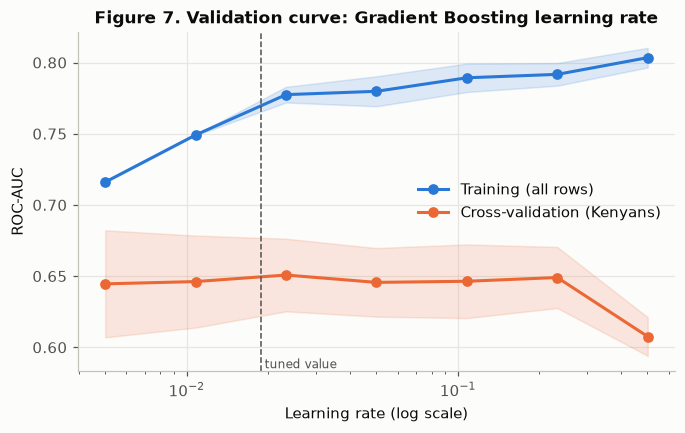

In [28]:
from sklearn.model_selection import validation_curve

best_hgb = hgb_search.best_estimator_
lrs = np.logspace(-2.3, -0.3, 7)
tr_sc, va_sc = validation_curve(best_hgb, X_train, y_train, param_name="model__learning_rate", param_range=lrs,
                                cv=KCV, scoring="roc_auc", n_jobs=-1)

fig, ax = plt.subplots(figsize=(7, 4))
for scores, label, color in [(tr_sc, "Training (all rows)", BLUE), (va_sc, "Cross-validation (Kenyans)", ORANGE)]:
    ax.plot(lrs, scores.mean(1), marker="o", color=color, label=label)
    ax.fill_between(lrs, scores.mean(1) - scores.std(1), scores.mean(1) + scores.std(1), color=color, alpha=0.15)
ax.set_xscale("log"); ax.set_xlabel("Learning rate (log scale)"); ax.set_ylabel("ROC-AUC")
ax.axvline(hgb_search.best_params_["model__learning_rate"], color=GREY_TEXT, ls="--", lw=1)
ax.text(hgb_search.best_params_["model__learning_rate"], ax.get_ylim()[0], " tuned value", color=GREY_TEXT, fontsize=8, va="bottom")
ax.legend(frameon=False); ax.set_title("Figure 7. Validation curve: Gradient Boosting learning rate")
savefig("fig07_validation_curve_lr")
plt.show()

> **Reading the output:** The Kenyan cross-validation score is **flat (≈0.645–0.651) for learning rates from 0.005 to 0.25**, and only drops at 0.5 (0.607), while the training score keeps rising from 0.72 to 0.80. That widening gap is overfitting at high learning rates. The tuned value (≈0.019) sits on the plateau. Together with the search table above, where the top 8 configurations are within 0.004 PR-AUC but each has a fold standard deviation of 0.02–0.04, this shows that **tuning gives only small gains here**: performance is limited by what the survey measures, not by hyperparameters. That is an honest and reportable finding. Tuning still helped Gradient Boosting's Kenyan PR-AUC from 0.351 (defaults) to 0.388, mainly through much larger leaves (`min_samples_leaf` ≈ 180), a strong regulariser.

## 13. Learning curves: more data, or a better model?

📘 **Concept: diagnosing bias vs variance.** A **learning curve** plots performance against the *amount of training data*.
- If the training and validation curves **converge at a low score**, the model has **high bias** (underfitting). More data won't help; you need better features or a more flexible model.
- If there is a **large persistent gap**, the model has **high variance** (overfitting). More data or more regularisation will help.
- If the validation curve is **still rising** at the right edge, collecting more data would pay off.

This is one of the rubric's required diagnostics, and here it also answers a Kenya question: *would more data (e.g. more Afrobarometer rounds) help?* We compare the simplest (Logistic Regression) and most flexible (Gradient Boosting) tuned models. The validation score is always on held-out Kenyans.

.venv/lib/python3.12/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(


.venv/lib/python3.12/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(


.venv/lib/python3.12/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(


.venv/lib/python3.12/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(


.venv/lib/python3.12/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(


.venv/lib/python3.12/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(


.venv/lib/python3.12/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(


.venv/lib/python3.12/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(


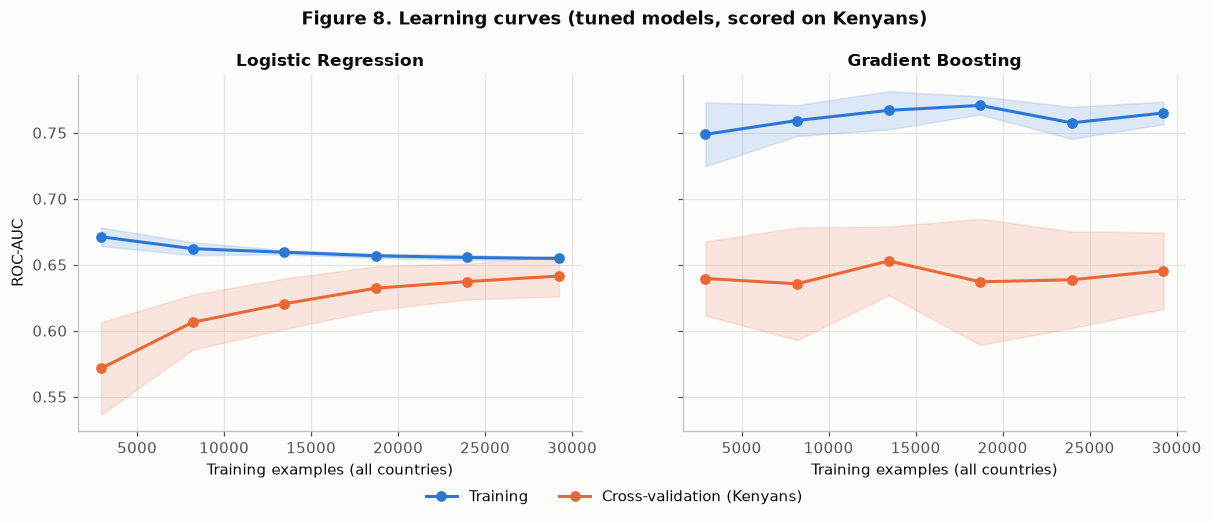

In [29]:
from sklearn.model_selection import learning_curve

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2), sharey=True)
for ax, name in zip(axes, ["Logistic Regression", "Gradient Boosting"]):
    sizes, tr, va = learning_curve(tuned[name].best_estimator_, X_train, y_train, cv=KCV, scoring="roc_auc",
                                   train_sizes=np.linspace(0.1, 1.0, 6), n_jobs=-1, shuffle=True, random_state=SEED)
    for scores, label, color in [(tr, "Training", BLUE), (va, "Cross-validation (Kenyans)", ORANGE)]:
        ax.plot(sizes, scores.mean(1), marker="o", color=color, label=label)
        ax.fill_between(sizes, scores.mean(1) - scores.std(1), scores.mean(1) + scores.std(1), color=color, alpha=0.15)
    ax.set_title(name); ax.set_xlabel("Training examples (all countries)")
axes[0].set_ylabel("ROC-AUC")
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, frameon=False, loc="lower center", ncol=2, bbox_to_anchor=(0.5, -0.08))
fig.suptitle("Figure 8. Learning curves (tuned models, scored on Kenyans)", y=1.02, fontweight="bold")
savefig("fig08_learning_curves_ml")
plt.show()

> **Reading the output:** **Logistic Regression:** the training score falls (0.67 → 0.655) while the Kenyan validation score rises (0.57 → 0.64), and the two have nearly **converged**. That is the signature of **high bias**: more rows will not help much; it needs richer features. (The `ConvergenceWarning`s printed here come from the saga solver at C = 10, explained in Section 12.) **Gradient Boosting:** the Kenyan validation score is already about 0.64 with 3,000 training rows and stays flat up to 29,000, while a gap of about 0.12 to the training score remains. Extra non-Kenyan rows beyond a few thousand do not improve predictions for Kenyans. What would help is **more information per person** (better features) or **more Kenyans** (e.g. pooling Afrobarometer rounds 7–10), not simply more rows from other countries.

## 14. Select the best traditional model on Kenyan validation data

📘 **Concept: model selection uses the validation set, never the test set.** The tuned models are compared on the **480 held-out Kenyan validation respondents**. We also tune the **decision threshold** there.

📘 **Concept: the decision threshold is a policy choice.** A classifier outputs a probability; turning it into "will/won't engage" needs a cut-off. 0.5 is arbitrary. For outreach planning, *missing* an excluded citizen may be worse than wrongly visiting an engaged one. We pick the threshold that maximises **F1** on Kenyan validation data (balancing precision and recall). A county could instead choose one that guarantees, say, 80% recall.

In [30]:
from sklearn.metrics import precision_recall_curve

def scores_of(model, X):
    return model.predict_proba(X)[:, 1] if hasattr(model, "predict_proba") else model.decision_function(X)

def best_f1_threshold(y, s):
    p, r, t = precision_recall_curve(y, s)
    f1 = 2 * p * r / np.clip(p + r, 1e-9, None)
    i = np.nanargmax(f1[:-1])
    return t[i], f1[i]

def evaluate(y, s, thr):
    pred = (s >= thr).astype(int)
    return {"ROC-AUC": roc_auc_score(y, s), "PR-AUC": average_precision_score(y, s),
            "accuracy": accuracy_score(y, pred), "balanced_acc": balanced_accuracy_score(y, pred),
            "precision": precision_score(y, pred, zero_division=0), "recall": recall_score(y, pred),
            "F1": f1_score(y, pred), "threshold": thr}

svm_pipe = Pipeline([("prep", make_preprocessor(NUM_COLS, CAT_COLS)), ("model", candidates["SVM (RBF, Nyström)"])]).fit(X_train, y_train)
ml_models = {name: s.best_estimator_ for name, s in tuned.items()}
ml_models["SVM (RBF, Nyström)"] = svm_pipe

val_rows, thresholds = {}, {}
for name, m in ml_models.items():
    s = scores_of(m, X_val)
    thresholds[name], _ = best_f1_threshold(yk_val, s[KEN_VAL])
    val_rows[name] = {**evaluate(yk_val, s[KEN_VAL], thresholds[name]),
                      "ROC-AUC (all countries)": roc_auc_score(y_val, s)}
val_table = pd.DataFrame(val_rows).T.sort_values("PR-AUC", ascending=False).round(3)
BEST_ML = val_table.index[0]
print("Best traditional model on Kenyan validation data:", BEST_ML)
val_table

Best traditional model on Kenyan validation data: Gradient Boosting


,ROC-AUC,PR-AUC,accuracy,balanced_acc,precision,recall,F1,threshold,ROC-AUC (all countries)
Gradient Boosting,0.702,0.450,0.610,0.658,0.369,0.754,0.496,0.422,0.677
Random Forest,0.696,0.446,0.623,0.658,0.376,0.730,0.496,0.430,0.671
Logistic Regression,0.679,0.417,0.556,0.646,0.345,0.828,0.487,0.403,0.641
"SVM (RBF, Nyström)",0.671,0.398,0.700,0.648,0.429,0.541,0.478,-0.002,0.664


> **Reading the output:** **Gradient Boosting is the best traditional model** on the 480 Kenyan validation respondents (ROC-AUC 0.702, PR-AUC 0.450), just ahead of Random Forest (0.696 / 0.446). At its F1-optimal threshold (≈0.42) it finds **75% of Kenyan contacters** with 37% precision. Logistic Regression's threshold trades precision for even higher recall (83%), a reminder that the threshold is a policy decision as much as a statistical one. The SVM threshold is near 0 because LinearSVC outputs *decision-function distances*, not probabilities. Note that every model scores **higher on Kenyans than on all countries** (e.g. 0.702 vs 0.677). With only 480 people, part of that is luck in this particular validation sample, which the test set will check.

## 15. Deep learning with TensorFlow / Keras

### 15.1 The `tf.data` input pipeline

📘 **Concept: why `tf.data`?** Passing NumPy arrays to `model.fit` works for small data, but `tf.data` is how production TensorFlow feeds models. It builds a **streaming pipeline**:
- `from_tensor_slices` turns arrays into a dataset of (features, label) examples.
- `shuffle(buffer)` randomises order each epoch, so the network doesn't learn the row order. Only the training set is shuffled.
- `batch(512)` groups examples. Gradients are averaged over a batch, which is faster and smoother than one example at a time.
- `cache()` keeps the prepared data in memory after the first epoch.
- `prefetch(AUTOTUNE)` prepares the next batch on the CPU **while** the model trains on the current one.

We **reuse the same fitted Scikit-Learn preprocessor** (imputation + scaling + one-hot), fitted on training data only. Both paradigms then see identical inputs, which makes the comparison fair.

📘 **Concept: which validation data for early stopping?** Keras checks the validation score after every epoch to decide when to stop. 480 Kenyans give a very jumpy per-epoch signal, so early stopping watches the **full validation set**. We then **select** between architectures using the **Kenyan validation rows**, as for the traditional models.

In [31]:
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"   # hide TensorFlow's C++ info logs
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, regularizers

warnings.filterwarnings("ignore", message=".*shuffle=True.*")  # we shuffle inside tf.data instead
keras.utils.set_random_seed(SEED)
tf.config.experimental.enable_op_determinism()
print("TensorFlow", tf.__version__)

dl_prep = make_preprocessor(NUM_COLS, CAT_COLS).fit(X_train)
Xtr = dl_prep.transform(X_train).astype("float32")
Xva = dl_prep.transform(X_val).astype("float32")
Xte = dl_prep.transform(X_test).astype("float32")
FEATURE_NAMES = dl_prep.get_feature_names_out()
N_FEATURES = Xtr.shape[1]

BATCH = 512
def make_dataset(X, y, training):
    ds = tf.data.Dataset.from_tensor_slices((X, y.astype("float32")))
    ds = ds.cache()
    if training:
        ds = ds.shuffle(buffer_size=len(y), seed=SEED, reshuffle_each_iteration=True)
    return ds.batch(BATCH).prefetch(tf.data.AUTOTUNE)

train_ds, val_ds, test_ds = make_dataset(Xtr, y_train, True), make_dataset(Xva, y_val, False), make_dataset(Xte, y_test, False)
xb, yb = next(iter(train_ds))
print(f"One batch: features {tuple(xb.shape)}, labels {tuple(yb.shape)}, positive share in batch = {yb.numpy().mean():.2f}")
print(train_ds.element_spec)

I0000 00:00:1792412602.120955  174083 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


I0000 00:00:1792412602.837374  174083 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


TensorFlow 2.21.0


One batch: features (512, 57), labels (512,), positive share in batch = 0.28
(TensorSpec(shape=(None, 57), dtype=tf.float32, name=None), TensorSpec(shape=(None,), dtype=tf.float32, name=None))


📘 **Concept: class weights in Keras.** Same idea as `class_weight="balanced"` in Scikit-Learn. The loss for each contacter example is multiplied by a larger weight, so the network can't minimise loss by predicting "no" for everyone.

In [32]:
from sklearn.utils.class_weight import compute_class_weight
cw = compute_class_weight("balanced", classes=np.array([0, 1]), y=y_train)
CLASS_WEIGHT = {0: float(cw[0]), 1: float(cw[1])}
print("Class weights:", {k: round(v, 3) for k, v in CLASS_WEIGHT.items()})

Class weights: {0: 0.692, 1: 1.803}


### 15.2 Model 1: Sequential API (multilayer perceptron)

📘 **Concept: anatomy of an MLP for tabular data.**
- `Dense(units)` is a fully connected layer: each neuron computes a weighted sum of all inputs.
- `ReLU` activation (max(0, x)) adds non-linearity. Without it, stacking layers collapses into one linear model.
- `Dropout(p)` randomly zeroes p% of neurons during training, which forces redundancy and reduces overfitting.
- `L2` weight regularisation penalises large weights, again to fight overfitting.
- `BatchNormalization` re-centres each layer's inputs, which often stabilises and speeds up training.
- **Output:** 1 neuron with **sigmoid** gives a probability between 0 and 1. The loss is **binary cross-entropy**.
- **Adam** is an adaptive optimiser; the **learning rate** sets the step size.

📘 **Concept: early stopping.** We train for up to 150 epochs but stop when validation PR-AUC hasn't improved for 12 epochs, then **restore the best weights**. This is regularisation by time: the network stops before it starts memorising.

In [33]:
def compile_model(model, lr):
    model.compile(optimizer=keras.optimizers.Adam(learning_rate=lr),
                  loss="binary_crossentropy",
                  metrics=[keras.metrics.AUC(name="auc"), keras.metrics.AUC(curve="PR", name="pr_auc"),
                           keras.metrics.Precision(name="precision"), keras.metrics.Recall(name="recall")])
    return model

def build_mlp(units=(64, 32), dropout=0.0, l2=0.0, batchnorm=False, lr=1e-3, name="mlp"):
    model = keras.Sequential(name=name)
    model.add(keras.Input(shape=(N_FEATURES,)))
    for u in units:
        model.add(layers.Dense(u, kernel_regularizer=regularizers.l2(l2) if l2 else None))
        if batchnorm:
            model.add(layers.BatchNormalization())
        model.add(layers.Activation("relu"))
        if dropout:
            model.add(layers.Dropout(dropout))
    model.add(layers.Dense(1, activation="sigmoid"))
    return compile_model(model, lr)

def fit(model, train, val, class_weight=CLASS_WEIGHT, epochs=150):
    callbacks = [keras.callbacks.EarlyStopping(monitor="val_pr_auc", mode="max", patience=12, restore_best_weights=True),
                 keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=5, min_lr=1e-5)]
    return model.fit(train, validation_data=val, epochs=epochs, class_weight=class_weight, callbacks=callbacks, verbose=0)

baseline_mlp = build_mlp(name="baseline_mlp")
baseline_mlp.summary()

Model: "baseline_mlp"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │         3,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 5,825 (22.75 KB)

 Trainable params: 5,825 (22.75 KB)

 Non-trainable params: 0 (0.00 B)

### 15.3 Experiment 5: neural-network architecture and regularisation

📘 **Concept: controlled experiments.** Change **one thing at a time** relative to a reference, so that any change in score can be attributed to that one change. Our runs:

| Run | What changes | Hypothesis |
|---|---|---|
| 1 baseline | 64→32, no regularisation | Reference point; may overfit |
| 2 + dropout | dropout 0.3 | Less overfitting |
| 3 + L2 + dropout | L2 = 1e-4 | Smoother weights |
| 4 wider/deeper | 256→128→64 | More capacity: does it help on ~33k rows? |
| 5 batch norm | 128→64 + BN | Faster, more stable training |
| 6 lower LR | 128→64, lr = 3e-4 | Slower but finer convergence |
| 7 no class weights | run 3 without weights | Shows the effect of imbalance handling on recall |

In [34]:
DL_RUNS = [
    dict(name="1_baseline", units=(64, 32)),
    dict(name="2_dropout", units=(64, 32), dropout=0.3),
    dict(name="3_dropout_l2", units=(64, 32), dropout=0.3, l2=1e-4),
    dict(name="4_wider_deeper", units=(256, 128, 64), dropout=0.3, l2=1e-4),
    dict(name="5_batchnorm", units=(128, 64), dropout=0.3, l2=1e-4, batchnorm=True),
    dict(name="6_low_lr", units=(128, 64), dropout=0.3, l2=1e-4, lr=3e-4),
    dict(name="7_no_class_weights", units=(64, 32), dropout=0.3, l2=1e-4, use_cw=False),
]

def dl_row(name, model, hist, s_val, seconds):
    thr, _ = best_f1_threshold(yk_val, s_val[KEN_VAL])
    m = evaluate(yk_val, s_val[KEN_VAL], thr)
    return {"run": name, "params": model.count_params(), "epochs": len(hist["loss"]),
            "Kenya val ROC-AUC": m["ROC-AUC"], "Kenya val PR-AUC": m["PR-AUC"],
            "Kenya recall@0.5": evaluate(yk_val, s_val[KEN_VAL], 0.5)["recall"], "Kenya F1@best thr": m["F1"],
            "all val ROC-AUC": roc_auc_score(y_val, s_val),
            "train-val AUC gap": max(hist["auc"]) - max(hist["val_auc"]), "seconds": seconds}

histories, dl_models, dl_rows = {}, {}, []
for cfg in DL_RUNS:
    cfg = dict(cfg); use_cw = cfg.pop("use_cw", True)
    keras.utils.set_random_seed(SEED)
    model = build_mlp(**cfg)
    t0 = time.time()
    hist = fit(model, train_ds, val_ds, class_weight=CLASS_WEIGHT if use_cw else None)
    s = model.predict(val_ds, verbose=0).ravel()
    histories[cfg["name"]], dl_models[cfg["name"]] = hist.history, model
    dl_rows.append(dl_row(cfg["name"], model, hist.history, s, time.time() - t0))
    print(f"{cfg['name']:20s} done: Kenya val PR-AUC {dl_rows[-1]['Kenya val PR-AUC']:.3f}, {len(hist.history['loss'])} epochs")
dl_results = pd.DataFrame(dl_rows).set_index("run").round(3)
dl_results.to_csv(RESULTS_DIR / "exp5_dl_runs.csv")
dl_results

1_baseline           done: Kenya val PR-AUC 0.413, 29 epochs


2_dropout            done: Kenya val PR-AUC 0.438, 45 epochs


3_dropout_l2         done: Kenya val PR-AUC 0.435, 64 epochs


4_wider_deeper       done: Kenya val PR-AUC 0.442, 37 epochs


5_batchnorm          done: Kenya val PR-AUC 0.433, 32 epochs


6_low_lr             done: Kenya val PR-AUC 0.434, 123 epochs


7_no_class_weights   done: Kenya val PR-AUC 0.429, 71 epochs


,params,epochs,Kenya val ROC-AUC,Kenya val PR-AUC,Kenya recall@0.5,Kenya F1@best thr,all val ROC-AUC,train-val AUC gap,seconds
run,,,,,,,,,
1_baseline,5825,29,0.692,0.413,0.582,0.510,0.665,0.061,4.480
2_dropout,5825,45,0.695,0.438,0.615,0.516,0.659,0.018,7.225
3_dropout_l2,5825,64,0.692,0.435,0.615,0.505,0.659,0.018,10.039
4_wider_deeper,56065,37,0.693,0.442,0.615,0.514,0.671,0.056,13.380
5_batchnorm,16513,32,0.693,0.433,0.590,0.502,0.665,0.020,8.403
6_low_lr,15745,123,0.686,0.434,0.582,0.488,0.656,0.019,23.692
7_no_class_weights,5825,71,0.697,0.429,0.098,0.519,0.671,0.026,10.501


> **Reading the output:** Every network lands between **0.686 and 0.697 Kenyan validation ROC-AUC**, the same ceiling the traditional models hit. Four lessons:
1. **Regularisation removes overfitting but doesn't raise the ceiling much.** The baseline's train–validation AUC gap of 0.061 drops to 0.018 with dropout (runs 2, 3), and Kenyan PR-AUC improves from 0.413 to about 0.437.
2. **More capacity helps a little.** The 256→128→64 network (56k parameters, run 4) is the best MLP on Kenyans (PR-AUC 0.442), still below Gradient Boosting's 0.450.
3. **Batch norm and a lower learning rate change training *dynamics*, not the final quality** here (0.433–0.434). The low learning rate simply needed 123 epochs instead of about 40.
4. **The most instructive run is 7, without class weights.** Its ROC-AUC (0.697) is as good as the others, so it *ranks* Kenyans just as well, but its **recall at the 0.5 threshold collapses to 0.10** (vs about 0.6). Class weights do not make a model smarter; they shift its scores so that the default threshold finds the minority class. Threshold tuning achieves the same effect.

📘 **Concept: reading training curves (the deep-learning learning curve).** For neural networks we plot loss and AUC **per epoch** for training and validation data:
- Validation loss rising while training loss keeps falling = **overfitting**. Early stopping catches this.
- Both curves flat and high = **underfitting**.
- A very noisy validation curve = the learning rate may be too high, or the batch too small.

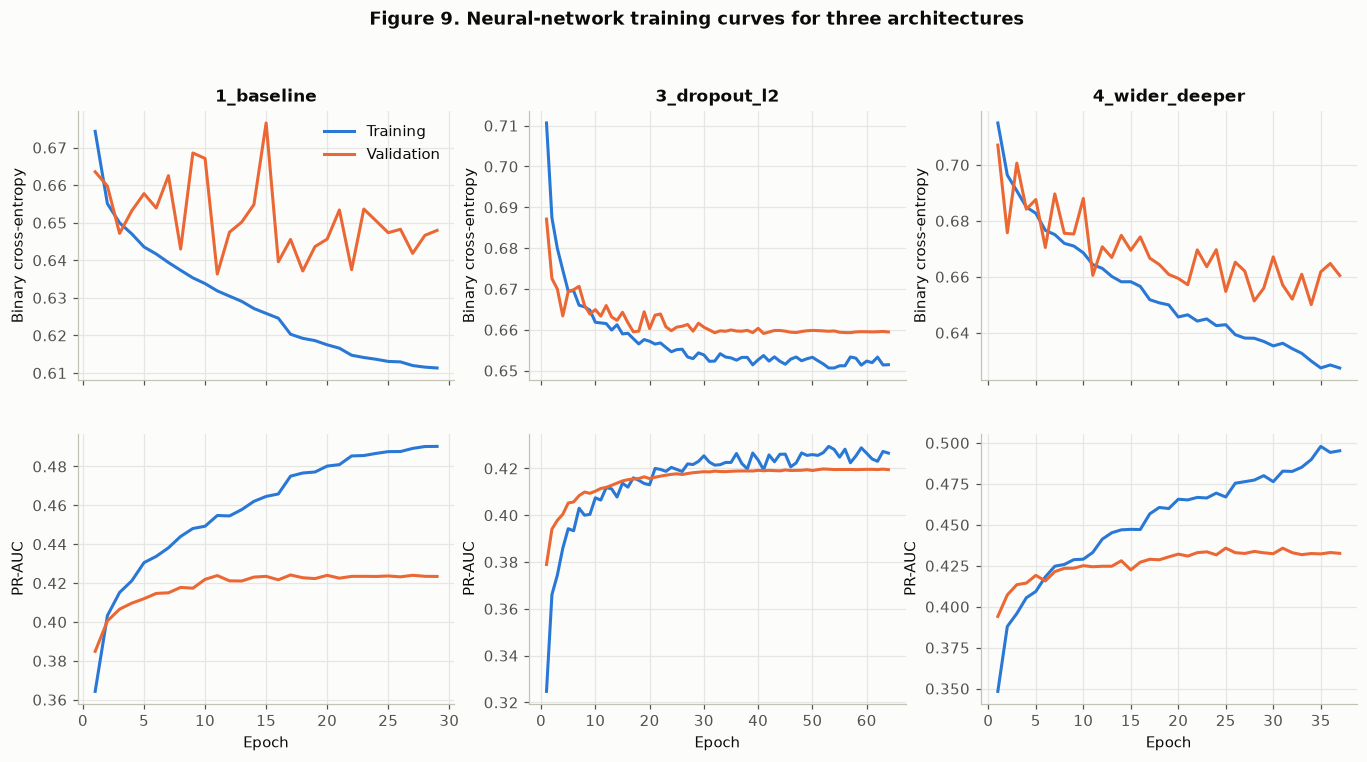

In [35]:
show = ["1_baseline", "3_dropout_l2", "4_wider_deeper"]
fig, axes = plt.subplots(2, 3, figsize=(15, 7), sharex="col")
for j, run in enumerate(show):
    h = histories[run]
    ep = np.arange(1, len(h["loss"]) + 1)
    for i, (metric, label) in enumerate([("loss", "Binary cross-entropy"), ("pr_auc", "PR-AUC")]):
        ax = axes[i, j]
        ax.plot(ep, h[metric], color=BLUE, label="Training")
        ax.plot(ep, h[f"val_{metric}"], color=ORANGE, label="Validation")
        ax.set_ylabel(label)
        if i == 0: ax.set_title(run)
        if i == 1: ax.set_xlabel("Epoch")
axes[0, 0].legend(frameon=False)
fig.suptitle("Figure 9. Neural-network training curves for three architectures", y=1.01, fontweight="bold")
savefig("fig09_dl_training_curves")
plt.show()

> **Reading the output:** (These curves use the full validation set, which early stopping monitors.) **Baseline (left):** a textbook case of overfitting. Training loss keeps falling while validation loss bottoms out around epoch 3 and then jumps around above it; the PR-AUC curves separate (0.49 training vs 0.42 validation). **Dropout + L2 (middle):** training and validation curves sit on top of each other, so regularisation has removed the overfitting. Training PR-AUC is even below validation at first, because dropout is active only during training. **Wide network (right):** a gap opens after about epoch 10, but validation PR-AUC keeps creeping up to about 0.43 before early stopping restores the best epoch. In all three, the validation curve flattens at 0.42–0.43, the same information ceiling seen in the Scikit-Learn learning curves.

### 15.4 Model 2: Functional API, a three-branch network that mirrors the data

📘 **Concept: why the Functional API?** `Sequential` can only stack layers in a straight line. The **Functional API** lets you build *graphs*: multiple inputs, branches, skip connections, multiple outputs. Here the architecture **mirrors the three levels of our data**:
- **Individual branch (deep):** the citizen's own barriers (Afrobarometer) pass through two Dense layers to learn interactions.
- **County branch:** the Kenyan county budget indicators (IBP county survey + Controller of Budget) pass through a small Dense layer.
- **Country branch:** the national context (IBP + World Bank) passes through a small Dense layer.
- The three branches are **concatenated**, then combined.
- **Wide path:** a direct linear connection from all inputs to the output (Cheng et al., 2016, "Wide & Deep"). It *memorises* simple linear effects while the deep part *generalises* interactions.

The `tf.data` pipeline now yields a **dictionary** of named inputs, `{"individual": ..., "county": ..., "country": ...}`, which Keras routes to the matching `Input` layers by name.

In [36]:
def feature_group(name):
    base = name.replace("missingindicator_", "")
    return "county" if base in COUNTY else "country" if base in COUNTRY else "individual"

GROUP_OF = np.array([feature_group(n) for n in FEATURE_NAMES])
BRANCHES = ["individual", "county", "country"]
for b in BRANCHES:
    print(f"{b:10s} {int((GROUP_OF == b).sum()):3d} inputs, e.g. {list(FEATURE_NAMES[GROUP_OF == b][:3])}")

def split_inputs(X):
    return {b: X[:, GROUP_OF == b] for b in BRANCHES}

def make_dataset_branches(X, y, training):
    ds = tf.data.Dataset.from_tensor_slices((split_inputs(X), y.astype("float32"))).cache()
    if training:
        ds = ds.shuffle(len(y), seed=SEED, reshuffle_each_iteration=True)
    return ds.batch(BATCH).prefetch(tf.data.AUTOTUNE)

train_ds3, val_ds3, test_ds3 = (make_dataset_branches(Xtr, y_train, True), make_dataset_branches(Xva, y_val, False),
                                make_dataset_branches(Xte, y_test, False))

def build_multilevel(lr=1e-3, dropout=0.3, l2=1e-4):
    reg = regularizers.l2(l2)
    inputs = {b: keras.Input(shape=(int((GROUP_OF == b).sum()),), name=b) for b in BRANCHES}

    x = layers.Dense(128, activation="relu", kernel_regularizer=reg, name="individual_dense_1")(inputs["individual"])
    x = layers.Dropout(dropout)(x)
    x = layers.Dense(64, activation="relu", kernel_regularizer=reg, name="individual_dense_2")(x)
    k = layers.Dense(8, activation="relu", kernel_regularizer=reg, name="county_dense")(inputs["county"])
    c = layers.Dense(8, activation="relu", kernel_regularizer=reg, name="country_dense")(inputs["country"])

    h = layers.Concatenate(name="merge_levels")([x, k, c])
    h = layers.Dense(32, activation="relu", kernel_regularizer=reg, name="joint_dense")(h)
    h = layers.Dropout(dropout)(h)
    deep_logit = layers.Dense(1, name="deep_logit")(h)

    wide_logit = layers.Dense(1, name="wide_logit")(layers.Concatenate(name="all_inputs")([inputs[b] for b in BRANCHES]))
    out = layers.Activation("sigmoid", name="p_contact")(layers.Add(name="wide_plus_deep")([deep_logit, wide_logit]))
    return compile_model(keras.Model(inputs=inputs, outputs=out, name="multilevel_wide_deep"), lr)

keras.utils.set_random_seed(SEED)
multilevel = build_multilevel()
multilevel.summary()

individual  37 inputs, e.g. ['service_proximity_index', 'infrastructure_index', 'ea_govt_office']
county      12 inputs, e.g. ['cbts_docs_published_z', 'cbts_pp_reports_z', 'cbts_citizens_budget_z']
country      8 inputs, e.g. ['ibp_transparency', 'ibp_participation', 'ibp_oversight']


Model: "multilevel_wide_deep"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ individual          │ (None, 37)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ individual_dense_1  │ (None, 128)       │      4,864 │ individual[0][0]  │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_13          │ (None, 128)       │          0 │ individual_dense… │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ county (InputLayer) │ (None, 12)        │          0 │ -                 │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ country             │ (None, 8)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ individual_dense_2  │ (None, 64)        │      8,256 │ dropout_13[0][0]  │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ county_dense        │ (None, 8)         │        104 │ county[0][0]      │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ country_dense       │ (None, 8)         │         72 │ country[0][0]     │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ merge_levels        │ (None, 80)        │          0 │ individual_dense… │
│ (Concatenate)       │                   │            │ county_dense[0][… │
│                     │                   │            │ country_dense[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ joint_dense (Dense) │ (None, 32)        │      2,592 │ merge_levels[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_14          │ (None, 32)        │          0 │ joint_dense[0][0] │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ all_inputs          │ (None, 57)        │          0 │ individual[0][0], │
│ (Concatenate)       │                   │            │ county[0][0],     │
│                     │                   │            │ country[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ deep_logit (Dense)  │ (None, 1)         │         33 │ dropout_14[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ wide_logit (Dense)  │ (None, 1)         │         58 │ all_inputs[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ wide_plus_deep      │ (None, 1)         │          0 │ deep_logit[0][0], │
│ (Add)               │                   │            │ wide_logit[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ p_contact           │ (None, 1)         │          0 │ wide_plus_deep[0… │
│ (Activation)        │                   │            │                   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 15,979 (62.42 KB)

 Trainable params: 15,979 (62.42 KB)

 Non-trainable params: 0 (0.00 B)

In [37]:
t0 = time.time()
ml_hist = fit(multilevel, train_ds3, val_ds3)
s = multilevel.predict(val_ds3, verbose=0).ravel()
histories["multilevel"], dl_models["multilevel"] = ml_hist.history, multilevel
dl_results.loc["8_functional_multilevel"] = pd.Series(dl_row("8_functional_multilevel", multilevel, ml_hist.history, s,
                                                             time.time() - t0)).drop("run")
dl_results = dl_results.astype(float).round(3)
dl_results.to_csv(RESULTS_DIR / "exp5_dl_runs.csv")
dl_results.sort_values("Kenya val PR-AUC", ascending=False)

,params,epochs,Kenya val ROC-AUC,Kenya val PR-AUC,Kenya recall@0.5,Kenya F1@best thr,all val ROC-AUC,train-val AUC gap,seconds
run,,,,,,,,,
8_functional_multilevel,15979.0,39.0,0.699,0.453,0.615,0.510,0.664,0.023,9.490
4_wider_deeper,56065.0,37.0,0.693,0.442,0.615,0.514,0.671,0.056,13.380
2_dropout,5825.0,45.0,0.695,0.438,0.615,0.516,0.659,0.018,7.225
3_dropout_l2,5825.0,64.0,0.692,0.435,0.615,0.505,0.659,0.018,10.039
6_low_lr,15745.0,123.0,0.686,0.434,0.582,0.488,0.656,0.019,23.692
5_batchnorm,16513.0,32.0,0.693,0.433,0.590,0.502,0.665,0.020,8.403
7_no_class_weights,5825.0,71.0,0.697,0.429,0.098,0.519,0.671,0.026,10.501
1_baseline,5825.0,29.0,0.692,0.413,0.582,0.510,0.665,0.061,4.480


> **Reading the output:** The three-branch Functional model is the **best neural network on Kenyans**: validation ROC-AUC **0.699 / PR-AUC 0.453**, slightly ahead of the best Sequential MLP (0.693 / 0.442) and level with Gradient Boosting (0.702 / 0.450). It is also small (16k parameters) and has a modest train–validation gap (0.023). Giving the county block its own small branch lets the network learn a compact "county effect" separately from individual barriers, rather than mixing 12 county inputs into every hidden unit. Two cautions: (1) the margin over run 4 (+0.011 PR-AUC) is well within the noise of 480 validation respondents; (2) choosing the best of 8 architectures on the same validation set slightly flatters the winner (the "winner's curse"). That is exactly why we keep a separate test set.

In [38]:
best_run = dl_results["Kenya val PR-AUC"].idxmax()
BEST_DL_KEY = "multilevel" if best_run == "8_functional_multilevel" else best_run
best_dl = dl_models[BEST_DL_KEY]
dl_val_ds, dl_test_ds = (val_ds3, test_ds3) if BEST_DL_KEY == "multilevel" else (val_ds, test_ds)
dl_val_scores = best_dl.predict(dl_val_ds, verbose=0).ravel()
DL_THRESHOLD, _ = best_f1_threshold(yk_val, dl_val_scores[KEN_VAL])
print(f"Best deep-learning model: {best_run}  (Kenya validation PR-AUC {dl_results.loc[best_run, 'Kenya val PR-AUC']:.3f}, "
      f"threshold {DL_THRESHOLD:.3f})")

Best deep-learning model: 8_functional_multilevel  (Kenya validation PR-AUC 0.453, threshold 0.502)


## 16. Final evaluation on the untouched Kenyan test set

📘 **Concept: one look at the test set.** Every choice so far (training source, feature set, algorithm, hyperparameters, architecture, threshold) was made on training/validation data. Now we score the final models **once** on the **480 held-out Kenyan test respondents**. These are the numbers reported in the Results section.

📘 **Concept: confidence intervals by bootstrapping.** 480 people is a small test set, so a single ROC-AUC hides how uncertain it is. The **bootstrap** resamples the test set with replacement 1,000 times, recomputes the score each time, and reports the middle 95% range. If two models' intervals overlap heavily, we cannot claim one is better.

We also report ROC-AUC on the whole multi-country test set as a secondary column.

In [39]:
def bootstrap_ci(y, s, metric=roc_auc_score, n=1000):
    rng = np.random.default_rng(SEED)
    vals = []
    for _ in range(n):
        b = rng.integers(0, len(y), len(y))
        if y[b].min() != y[b].max():
            vals.append(metric(y[b], s[b]))
    return np.percentile(vals, [2.5, 97.5])

test_scores = {name: scores_of(m, X_test) for name, m in ml_models.items()}
test_scores[f"DL: {best_run}"] = best_dl.predict(dl_test_ds, verbose=0).ravel()
thresholds[f"DL: {best_run}"] = DL_THRESHOLD

yk_test = y_test[KEN_TEST]
rows = {}
for name, s in test_scores.items():
    lo, hi = bootstrap_ci(yk_test, s[KEN_TEST])
    rows[name] = {**evaluate(yk_test, s[KEN_TEST], thresholds[name]), "ROC-AUC 95% CI": f"{lo:.3f}–{hi:.3f}",
                  "ROC-AUC (all countries)": roc_auc_score(y_test, s), "PR-AUC (all countries)": average_precision_score(y_test, s)}
test_table = pd.DataFrame(rows).T.sort_values("PR-AUC", ascending=False)
test_table = test_table.apply(lambda c: c.astype(float).round(3) if c.name != "ROC-AUC 95% CI" else c)
test_table.to_csv(RESULTS_DIR / "final_test_metrics_kenya.csv")
print(f"Kenyan test set: {len(yk_test):,} citizens, {yk_test.mean():.1%} contacted their MCA (PR-AUC baseline = {yk_test.mean():.3f})")
test_table

Kenyan test set: 480 citizens, 25.6% contacted their MCA (PR-AUC baseline = 0.256)


,ROC-AUC,PR-AUC,accuracy,balanced_acc,precision,recall,F1,threshold,ROC-AUC 95% CI,ROC-AUC (all countries),PR-AUC (all countries)
Gradient Boosting,0.654,0.430,0.554,0.604,0.328,0.707,0.448,0.422,0.595–0.707,0.686,0.457
DL: 8_functional_multilevel,0.659,0.394,0.629,0.633,0.371,0.642,0.470,0.502,0.600–0.712,0.676,0.431
Random Forest,0.665,0.386,0.575,0.632,0.347,0.748,0.474,0.430,0.608–0.717,0.678,0.444
"SVM (RBF, Nyström)",0.648,0.375,0.648,0.633,0.381,0.602,0.467,-0.002,0.591–0.699,0.676,0.435
Logistic Regression,0.652,0.359,0.527,0.607,0.323,0.772,0.456,0.403,0.593–0.703,0.661,0.405


> **Reading the output:** On the 480 untouched Kenyan test respondents:
- **Gradient Boosting has the best PR-AUC (0.430, about 1.7× the random baseline of 0.256)**, with ROC-AUC 0.654. Random Forest has the best ROC-AUC (0.665) and the three-branch neural network is close (0.659), but **all five 95% confidence intervals overlap almost completely** (e.g. Gradient Boosting 0.595–0.707). On 480 Kenyans **we cannot statistically separate the models**; we can say that all of them clearly beat random guessing.
- **Scores dropped from validation to test** (Gradient Boosting 0.702 → 0.654). That is what small samples and the winner's curse look like in practice, and why the test set is touched only once.
- **On all countries** the same models score higher and more stably (Gradient Boosting 0.686 / 0.457 on 6,500 people). **Kenyans are slightly harder to predict than the average respondent**, consistent with Experiment 1.
- **Traditional ML vs deep learning:** the best network matches the tree ensembles on ROC-AUC but trails Gradient Boosting on PR-AUC (0.394 vs 0.430). It took longer to build and tune and is harder to explain. This matches recent benchmarks showing tree-based ensembles still match or beat neural networks on medium-sized tabular data (Grinsztajn et al., 2022; Shwartz-Ziv & Armon, 2022). We therefore keep **Gradient Boosting as the main model.**

📘 **Concept: ROC vs Precision–Recall curves.**
- The **ROC curve** plots True-Positive Rate against False-Positive Rate across all thresholds. The diagonal is random guessing.
- The **PR curve** plots Precision against Recall. Its random baseline is the horizontal line at the positive rate. With imbalanced classes, the PR curve shows differences that ROC hides, because ROC's x-axis is diluted by the many true negatives.

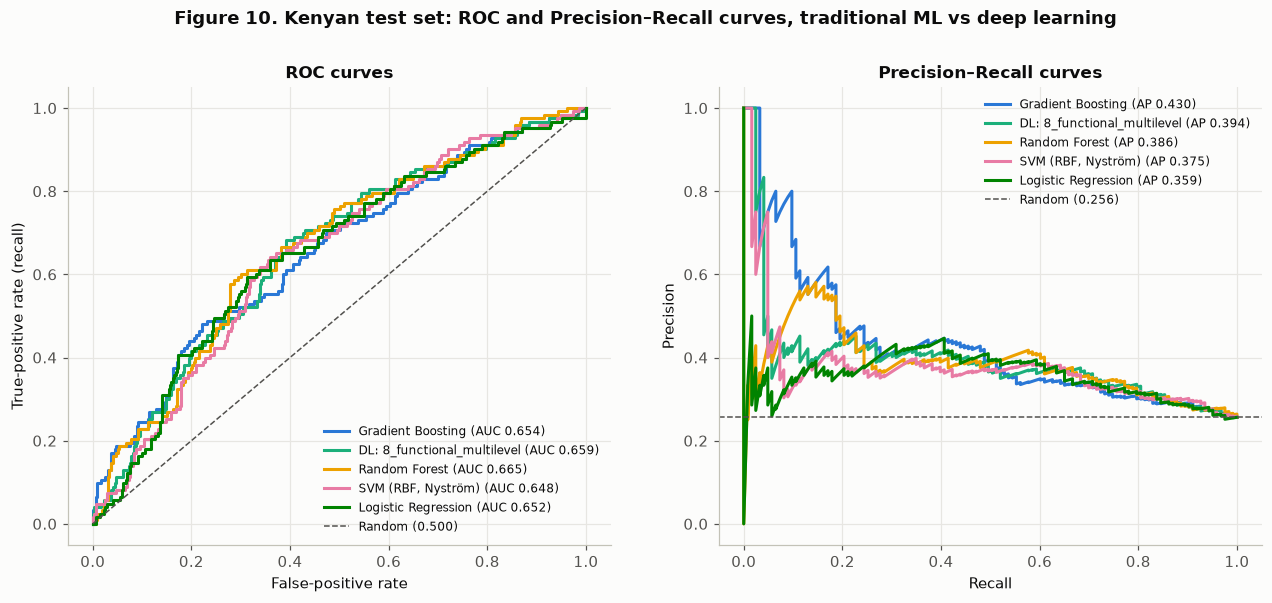

In [40]:
from sklearn.metrics import roc_curve

fig, axes = plt.subplots(1, 2, figsize=(14, 5.4))
for color, name in zip([c for c in PALETTE if c != ORANGE], test_table.index):   # orange is reserved for Kenya
    s = test_scores[name][KEN_TEST]
    fpr, tpr, _ = roc_curve(yk_test, s)
    axes[0].plot(fpr, tpr, color=color, label=f"{name} (AUC {roc_auc_score(yk_test, s):.3f})")
    p, r, _ = precision_recall_curve(yk_test, s)
    axes[1].plot(r, p, color=color, label=f"{name} (AP {average_precision_score(yk_test, s):.3f})")
axes[0].plot([0, 1], [0, 1], color=GREY_TEXT, ls="--", lw=1, label="Random (0.500)")
axes[1].axhline(yk_test.mean(), color=GREY_TEXT, ls="--", lw=1, label=f"Random ({yk_test.mean():.3f})")
axes[0].set(xlabel="False-positive rate", ylabel="True-positive rate (recall)", title="ROC curves")
axes[1].set(xlabel="Recall", ylabel="Precision", title="Precision–Recall curves")
for ax in axes: ax.legend(frameon=False, fontsize=8, loc="lower right" if ax is axes[0] else "upper right")
fig.suptitle("Figure 10. Kenyan test set: ROC and Precision–Recall curves, traditional ML vs deep learning", y=1.01, fontweight="bold")
savefig("fig10_roc_pr_curves_kenya")
plt.show()

📘 **Concept: the confusion matrix makes errors concrete.** Four cells:
- **True negatives:** correctly predicted "did not contact".
- **False positives:** predicted contact, but the person never did. In outreach terms, an excluded citizen who *looks* engaged **gets missed by targeted outreach**.
- **False negatives:** predicted no contact, but they did. Outreach is "wasted" on someone already engaged.
- **True positives:** correctly predicted contact.

We show **row-normalised** percentages (the share of each *true* class), so the imbalance doesn't hide the minority-class performance.

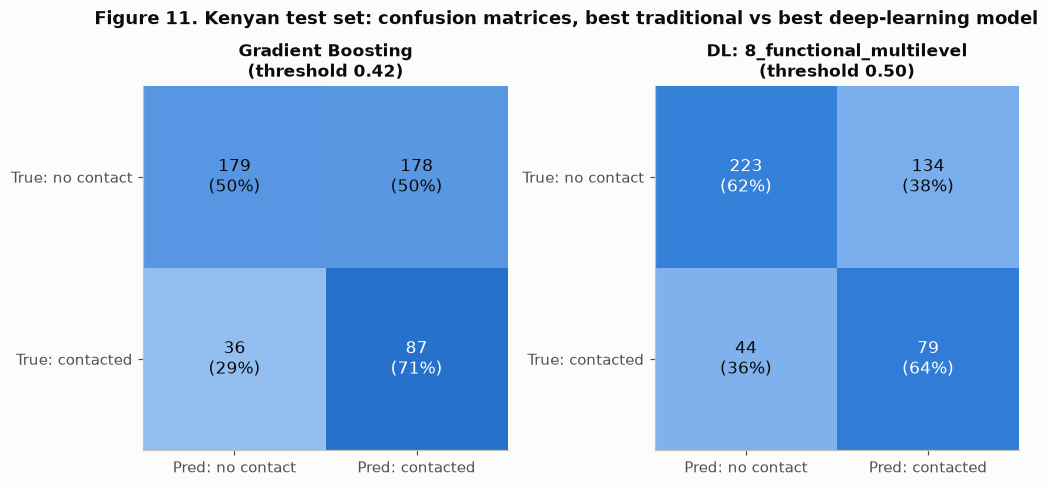

--- Gradient Boosting (Kenyan test set) ---
              precision    recall  f1-score   support

  no contact      0.833     0.501     0.626       357
   contacted      0.328     0.707     0.448       123

    accuracy                          0.554       480
   macro avg      0.580     0.604     0.537       480
weighted avg      0.703     0.554     0.580       480

--- DL: 8_functional_multilevel (Kenyan test set) ---
              precision    recall  f1-score   support

  no contact      0.835     0.625     0.715       357
   contacted      0.371     0.642     0.470       123

    accuracy                          0.629       480
   macro avg      0.603     0.633     0.592       480
weighted avg      0.716     0.629     0.652       480



In [41]:
from sklearn.metrics import confusion_matrix, classification_report

pair = [BEST_ML, f"DL: {best_run}"]
blues = LinearSegmentedColormap.from_list("seq", ["#f0f6fe", "#86b6ef", "#2a78d6", "#104281"])
fig, axes = plt.subplots(1, 2, figsize=(11, 4.3))
for ax, name in zip(axes, pair):
    pred = (test_scores[name][KEN_TEST] >= thresholds[name]).astype(int)
    cm = confusion_matrix(yk_test, pred)
    cm_pct = cm / cm.sum(axis=1, keepdims=True)
    ax.imshow(cm_pct, cmap=blues, vmin=0, vmax=1)
    for i in range(2):
        for j in range(2):
            ax.text(j, i, f"{cm[i, j]:,}\n({cm_pct[i, j]:.0%})", ha="center", va="center",
                    color="white" if cm_pct[i, j] > 0.55 else "#0b0b0b", fontsize=11)
    ax.set_xticks([0, 1], ["Pred: no contact", "Pred: contacted"]); ax.set_yticks([0, 1], ["True: no contact", "True: contacted"])
    ax.grid(False); ax.set_title(f"{name}\n(threshold {thresholds[name]:.2f})")
fig.suptitle("Figure 11. Kenyan test set: confusion matrices, best traditional vs best deep-learning model", y=1.04, fontweight="bold")
savefig("fig11_confusion_matrices_kenya")
plt.show()

for name in pair:
    print(f"--- {name} (Kenyan test set) ---")
    print(classification_report(yk_test, (test_scores[name][KEN_TEST] >= thresholds[name]).astype(int),
                                target_names=["no contact", "contacted"], digits=3))

> **Reading the output:** The two models sit at **different operating points**. **Gradient Boosting** (threshold 0.42) finds **71% of Kenyan contacters** (87 of 123) but clears only **50% of non-contacters**, so its precision is 33%. The **neural network** (threshold 0.50) is more balanced: it finds 64% of contacters and clears 62% of non-contacters (precision 37%). Neither is "right"; the choice depends on the cost of each error. Suppose a county uses Gradient Boosting to prioritise outreach to the 215 Kenyans it predicts will **not** contact their MCA. Only 36 of them (17%) actually did, so most outreach would reach genuinely disconnected citizens. That is acceptable for low-cost outreach such as SMS, radio or ward barazas, but never for anything that withholds services.

## 17. Experiment 6: can the model predict engagement in a county it has never seen?

📘 **Concept: from individual predictions to county-level insight.** A county government or NGO wants to know which **counties** have the most excluded citizens, including counties where nobody has been surveyed. Afrobarometer interviewed as few as 8 people in some counties, so a model that can rank *unseen* counties from their budget data and their residents' characteristics would be genuinely useful.

📘 **Concept: grouped cross-validation, and a leak that is easy to miss.** The obvious approach is ordinary cross-validation over Kenyans: train on 80% of Kenyans, predict the other 20%, average the predictions by county, and compare with the observed county rates. **That leaks.** Each person's prediction comes from a model trained on the *other* 80% of their own county's respondents. The county features take one unique value per county, so they act like a county ID, and the model memorises each county's average. The "observed" county rate is computed from those same neighbours, so prediction and observation share most of their labels, and the correlation looks spectacular for the wrong reason. (An earlier draft of this notebook made exactly this mistake and reported ρ ≈ 0.87.)

The fix is **`GroupKFold` with county as the group**. All respondents from a county are held out *together*, so the model has never seen anyone from the county it is predicting. We run it twice, with and without the county budget features (sets D and C, same tuned model), to ask: **does county budget data help rank unseen counties?**

📘 **Concept: calibration.** Training with `class_weight="balanced"` tells the model that contacters are about 2.6× more important, which **pushes all predicted probabilities upwards**. The scores still *rank* people well (that is what ROC-AUC measures), but a score of 0.5 no longer means "50% chance". So we compare **ranks** (Spearman ρ), not raw values, and draw no y = x line. If you needed true probabilities, you would recalibrate with `CalibratedClassifierCV`.

⚠️ Each county has only 8–264 respondents, so observed rates are noisy. We show counties with n ≥ 24.

In [42]:
from sklearn.base import clone
from sklearn.model_selection import GroupKFold

full = df.reset_index(drop=True)
ken_pos, other_pos = np.flatnonzero(full.is_kenya.values), np.flatnonzero(~full.is_kenya.values)

def leave_counties_out(fs):
    """Score every Kenyan with a model that never saw anyone from their county."""
    pipe = clone(ml_models[BEST_ML]).set_params(prep=make_preprocessor(**FEATURE_SETS[fs]))
    scores = np.full(len(full), np.nan)
    for k_tr, k_te in GroupKFold(n_splits=5).split(ken_pos, groups=full["region"].values[ken_pos]):
        tr, te = np.concatenate([other_pos, ken_pos[k_tr]]), ken_pos[k_te]
        model = clone(pipe).fit(full.loc[tr, cols(fs)], full.loc[tr, "contacted"])
        scores[te] = scores_of(model, full.loc[te, cols(fs)])
    return scores[ken_pos]

ken_lco = full.loc[ken_pos, ["region", "contacted"]].copy()
ken_lco["with county data (D)"] = leave_counties_out(FS)
ken_lco["without county data (C)"] = leave_counties_out("C. B + country context")

county = (ken_lco.groupby("region")
          .agg(n=("contacted", "size"), observed=("contacted", "mean"),
               **{c: (c, "mean") for c in ["with county data (D)", "without county data (C)"]})
          .query("n >= 24").sort_values("observed"))
summary = pd.DataFrame({c: {"individual ROC-AUC (all Kenyans)": roc_auc_score(ken_lco["contacted"], ken_lco[c]),
                            f"county Spearman ρ ({len(county)} counties)": county[[c, "observed"]].corr(method="spearman").iloc[0, 1]}
                        for c in ["with county data (D)", "without county data (C)"]}).T.round(3)
summary.to_csv(RESULTS_DIR / "exp6_unseen_counties.csv")
summary

,individual ROC-AUC (all Kenyans),county Spearman ρ (42 counties)
with county data (D),0.644,0.130
without county data (C),0.642,0.009


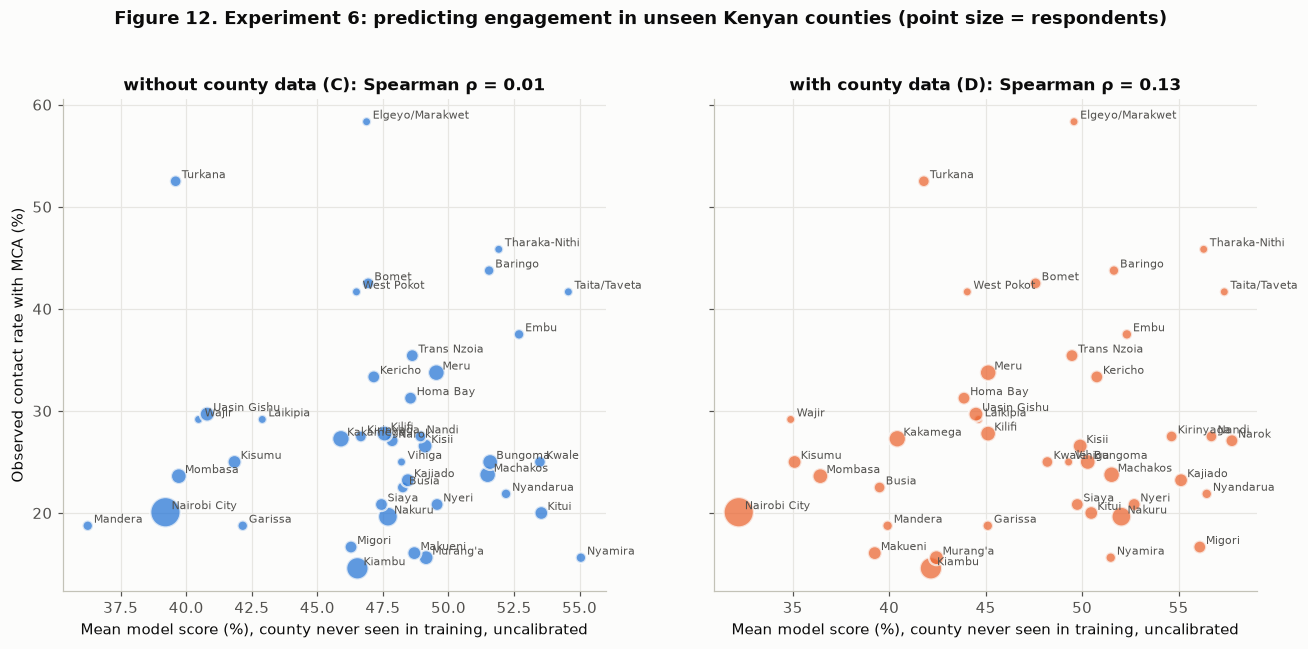

In [43]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.8), sharey=True)
for ax, col, color in [(axes[0], "without county data (C)", BLUE), (axes[1], "with county data (D)", ORANGE)]:
    ax.scatter(county[col] * 100, county["observed"] * 100, s=county["n"] * 1.5, color=color, alpha=0.75,
               edgecolor="#fcfcfb", linewidth=1.5)
    for reg, r in county.iterrows():
        ax.annotate(str(reg), (r[col] * 100, r["observed"] * 100), xytext=(4, 2), textcoords="offset points",
                    fontsize=7, color=GREY_TEXT)
    ax.set(xlabel="Mean model score (%), county never seen in training, uncalibrated",
           title=f"{col}: Spearman ρ = {summary.loc[col].iloc[1]:.2f}")
axes[0].set_ylabel("Observed contact rate with MCA (%)")
fig.suptitle("Figure 12. Experiment 6: predicting engagement in unseen Kenyan counties (point size = respondents)",
             y=1.02, fontweight="bold")
savefig("fig12_kenya_unseen_counties")
plt.show()
county.round(3).to_csv(RESULTS_DIR / "kenya_counties.csv");

> **Reading the output:** Under the honest leave-counties-out test, **the model cannot rank counties it has never seen.** Without county data the county-level rank correlation is **ρ = 0.01**. Adding the IBP county survey and Controller of Budget data raises it to **ρ = 0.13**, a hint of signal, but with 42 counties a correlation needs to reach about 0.30 to be distinguishable from chance. For individuals the county data adds nothing either (ROC-AUC 0.644 vs 0.642). The most engaged counties, **Elgeyo-Marakwet (58%) and Turkana (52%)**, are predicted as average. Nairobi, with its extreme pending bills, gets the lowest prediction with county data, which happens to be roughly right (20% observed).

Compare this with the **ρ ≈ 0.87** the leaky random-fold version produced: a spectacular-looking result that was entirely an artefact of the evaluation design. **How you split the data decides what question you are actually answering.**

**What this means for Kenya:** differences between counties in MCA contact (6%–58%) are driven by things that neither the survey's individual questions nor published budget data capture. Candidates include how active individual MCAs are, local politics and patronage networks, and simply noise from small county samples (8–264 respondents). **Published budget-transparency data cannot substitute for asking citizens.** To target outreach county by county, you need county-level survey data, for example from pooled Afrobarometer rounds or KNBS surveys.

## 18. What drives the predictions for Kenyans? Explainability

📘 **Concept: permutation importance.** Shuffle one feature's values across rows, which breaks its relationship with the target, and measure how much the score drops. A big drop means the model relies on that feature. Unlike tree "impurity" importance, it is **model-agnostic**, is computed on **held-out data**, and isn't biased towards high-cardinality features. We permute the *original* columns (before one-hot encoding), so the results speak the language of the problem statement.

We compute it on **held-out Kenyans only** (validation + test, about 960 people; neither was used for fitting) and repeat each shuffle 10 times, because small samples make importance noisy.

⚠️ Importance ≠ causation. "Age is important" means it *predicts* contact, not that age *causes* it.

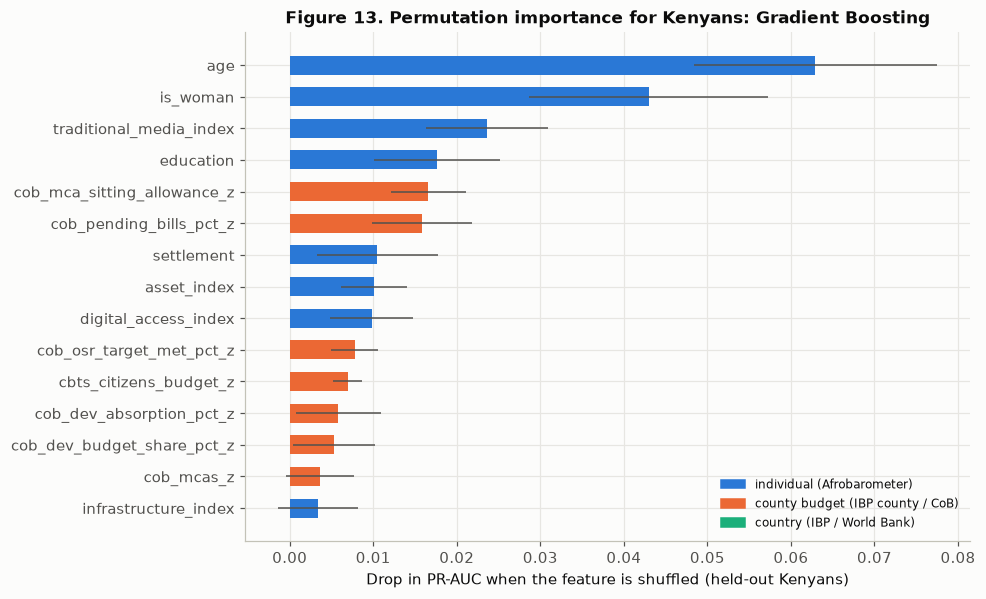

source
country          0.0000
county budget    0.0621
individual       0.1866


In [44]:
from sklearn.inspection import permutation_importance

ken_holdout = pd.concat([val_df[KEN_VAL], test_df[KEN_TEST]])
pi = permutation_importance(ml_models[BEST_ML], ken_holdout[FEATURES], ken_holdout["contacted"], scoring="average_precision",
                            n_repeats=10, random_state=SEED, n_jobs=-1)
imp = pd.DataFrame({"feature": FEATURES, "mean": pi.importances_mean, "std": pi.importances_std}).sort_values("mean")
imp["source"] = imp["feature"].map(lambda f: "county budget" if f in COUNTY else "country" if f in COUNTRY else "individual")
imp.to_csv(RESULTS_DIR / "permutation_importance_kenya.csv", index=False)

top = imp.tail(15)
colors = top["source"].map({"individual": BLUE, "county budget": ORANGE, "country": AQUA})
fig, ax = plt.subplots(figsize=(8.5, 6))
ax.barh(top["feature"], top["mean"], xerr=top["std"], color=colors, height=0.6, error_kw=dict(ecolor=GREY_TEXT, lw=1))
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color=c, label=src) for src, c in [("individual (Afrobarometer)", BLUE),
                                                            ("county budget (IBP county / CoB)", ORANGE),
                                                            ("country (IBP / World Bank)", AQUA)]],
          frameon=False, loc="lower right", fontsize=8)
ax.set_xlabel("Drop in PR-AUC when the feature is shuffled (held-out Kenyans)")
ax.set_title(f"Figure 13. Permutation importance for Kenyans: {BEST_ML}")
savefig("fig13_permutation_importance_kenya")
plt.show()
print(imp.groupby("source")["mean"].sum().round(4).rename("total importance").to_string())

> **Reading the output:** For Kenyans, the two dominant predictors are **age** (shuffling it drops PR-AUC by 0.063) and **gender** (0.043), followed by **traditional media use** (radio/TV/newspaper, 0.024) and **education** (0.018). Next come two **county budget features: MCA sitting allowances and pending bills** (about 0.016 each). Summed by source, individual features carry about 0.19 and county budget features about 0.06. **Country features carry exactly 0**, which is expected: every Kenyan has the same country values, so shuffling them among Kenyans changes nothing.

How should the county importance be read? The 12 county columns together take only 47 distinct combinations, so the model can use them partly as a **county identifier**, learning "respondents from this county tend to contact their MCA" rather than a general rule about budgets. Experiment 6 tests which it is. The "distance" (`service_proximity_index`) and infrastructure features matter little. **In Kenya, exclusion from MCA contact is mostly about who you are (young, female, less informed, less educated), not how far you live from services.** Permutation importance measures *predictive reliance*, not causal effect.

📘 **Concept: partial dependence plots (PDP).** Importance tells you *which* features matter; a PDP tells you *how*. It shows the model's average predicted probability as one feature varies while the others keep their observed values. Look for direction (up/down), shape (linear, saturating, threshold), and size of effect.

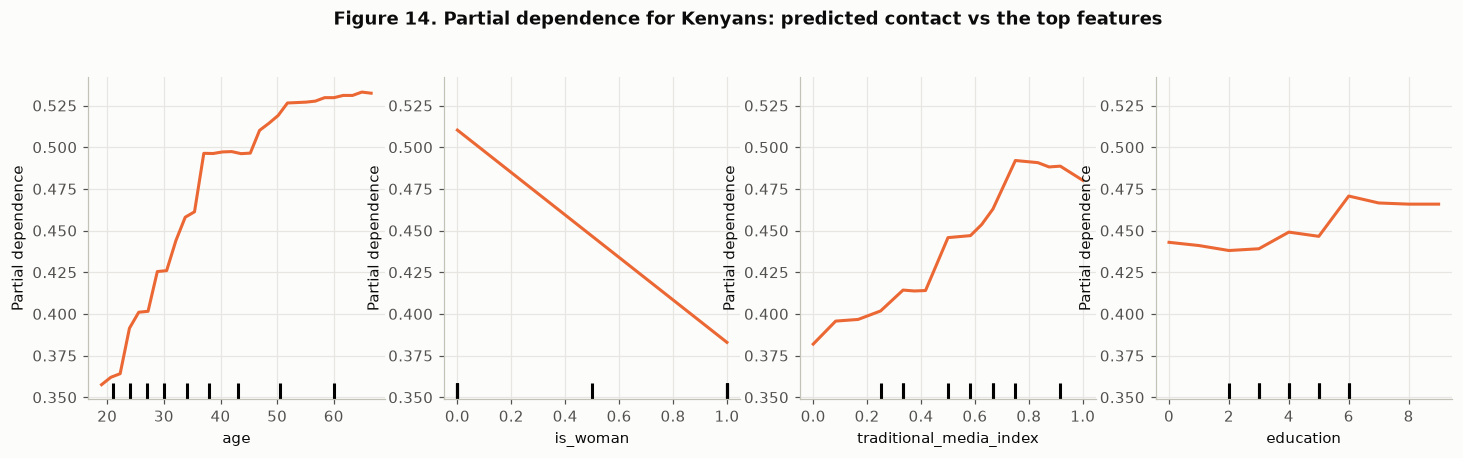

In [45]:
from sklearn.inspection import PartialDependenceDisplay

pdp_feats = [f for f in imp.sort_values("mean", ascending=False)["feature"] if f in NUM_COLS][:4]
# PDPs build a grid of values for each feature, so integer columns (0/1 flags) must be float first
ken_float = ken_holdout[FEATURES].astype({c: float for c in NUM_COLS})
fig, axes = plt.subplots(1, 4, figsize=(16, 3.8))
PartialDependenceDisplay.from_estimator(ml_models[BEST_ML], ken_float, pdp_feats, ax=axes,
                                        line_kw={"color": ORANGE, "lw": 2}, grid_resolution=30)
fig.suptitle("Figure 14. Partial dependence for Kenyans: predicted contact vs the top features", y=1.04, fontweight="bold")
savefig("fig14_partial_dependence_kenya")
plt.show()

> **Reading the output:** Holding everything else at observed values: the score **rises steeply with age from about 20 (0.36) to about 37 (0.50)** and keeps creeping up to 0.53 at 50+, so **young Kenyans are the least connected group**. Being a **woman lowers the score by about 0.13** (0.51 → 0.38), the largest single shift. **Traditional media use** pushes the score up steadily (0.38 → 0.49): Kenyans who follow radio or TV news are more likely to reach their MCA. **Education** matters only at the top: the score rises at level 6+ (post-secondary). Scores are uncalibrated (class weights inflate them), so read **the shape and direction**, not the absolute level.

## 19. Fairness and error analysis: which Kenyans does the model fail?

📘 **Concept: group-wise error rates.** A tool meant to *reduce* exclusion must not itself be worse for already-excluded groups. On the Kenyan test set we compare **recall** (the share of actual contacters the model finds) and **precision** across women/men, **youth (18–34, the constitutional definition of youth in Kenya) vs older adults**, rural/urban residents, and interview language. Large gaps would mean the model's errors fall unevenly. That would need to be fixed (e.g. group-specific thresholds or more data) before any real deployment. With only 480 test respondents, treat gaps under about 0.10 as noise.

In [46]:
kt = test_df[KEN_TEST].assign(score=test_scores[BEST_ML][KEN_TEST])
kt["pred"] = (kt["score"] >= thresholds[BEST_ML]).astype(int)
kt["gender"] = np.where(kt["is_woman"] == 1, "Women", "Men")
kt["age band"] = np.where(kt["age"] < 35, "Youth 18–34", "35+")
kt["language"] = np.where(kt["interview_in_legal_language"] == 1, "English", "Swahili / local language")

rows = []
for col in ["gender", "age band", "settlement", "language"]:
    for grp, g in kt.groupby(col):
        rows.append({"dimension": col, "group": grp, "n": len(g), "true contact rate": g["contacted"].mean(),
                     "predicted positive rate": g["pred"].mean(),
                     "recall": recall_score(g["contacted"], g["pred"], zero_division=0),
                     "precision": precision_score(g["contacted"], g["pred"], zero_division=0),
                     "ROC-AUC": roc_auc_score(g["contacted"], g["score"])})
fair = pd.DataFrame(rows).round(3)
fair.to_csv(RESULTS_DIR / "fairness_audit_kenya.csv", index=False)
fair

,dimension,group,n,true contact rate,predicted positive rate,recall,precision,ROC-AUC
0,gender,Men,236,0.318,0.843,0.867,0.327,0.612
1,gender,Women,244,0.197,0.270,0.458,0.333,0.640
2,age band,35+,240,0.333,0.758,0.838,0.368,0.621
3,age band,Youth 18–34,240,0.179,0.346,0.465,0.241,0.610
4,settlement,Rural,335,0.278,0.642,0.763,0.330,0.649
5,settlement,Urban,145,0.207,0.345,0.533,0.320,0.639
6,language,English,109,0.294,0.459,0.688,0.440,0.717
7,language,Swahili / local language,371,0.245,0.580,0.714,0.302,0.634


> **Reading the output:** **Gender and age are the critical gaps.** Among Kenyans, the model finds **87% of men who contacted their MCA but only 46% of women**, and **84% of contacters aged 35+ but only 47% of youth (18–34)**. It flags 84% of men as likely contacters but only 27% of women. Rural vs urban recall also differs (0.76 vs 0.53). **Language shows no gap** (0.69 English vs 0.71 Swahili/local). Notice that **ROC-AUC *within* each group is similar (0.61–0.65)**: the model ranks women among women about as well as men among men. The gap comes from one global threshold applied to groups with different base rates, and from the model leaning heavily on gender and age.

There are two ways to read this. (1) As an **exclusion detector**, the model correctly identifies young people and women as under-engaged, which is useful for targeting outreach. (2) As a predictor, it **stereotypes**, under-recognising the young women who *do* engage. Mitigations: group-specific thresholds, re-weighting, or always reporting per-group metrics alongside any deployment. With about 240 people per group, treat these numbers as indicative.

## 20. Using the model on a Kenyan citizen

📘 **Concept: inference.** A trained pipeline is a function: raw features in, probability out. Because the preprocessing lives *inside* the pipeline, you pass raw values, with no manual scaling. Here we compare Kenyan profiles from the test set: three the model is most confident are excluded, and three it is most confident are engaged.

In [47]:
show_cols = ["region", "settlement", "age", "is_woman", "education", "freq_internet_use", "service_proximity_index",
             "interview_lang_group", "lived_poverty_index", "cbts_transparency_score", "score", "contacted"]
pd.concat([kt.nsmallest(3, "score"), kt.nlargest(3, "score")])[show_cols].round(2)

,region,settlement,age,is_woman,education,freq_internet_use,service_proximity_index,interview_lang_group,lived_poverty_index,cbts_transparency_score,score,contacted
6256,Nairobi City,Urban,18.0,1,7.0,4.0,2.0,English,0.0,60.5,0.16,0
6248,Kiambu,Urban,24.0,1,5.0,0.0,3.0,English,0.0,45.6,0.16,0
6305,Makueni,Rural,30.0,1,2.0,0.0,1.0,Swahili,0.0,71.3,0.16,1
6422,Mandera,Rural,52.0,0,5.0,4.0,4.0,English,1.6,43.1,0.80,1
6240,Narok,Rural,42.0,0,6.0,4.0,6.0,English,2.4,56.7,0.77,1
6100,Lamu,Rural,63.0,0,6.0,4.0,3.0,Swahili,1.4,58.1,0.77,1


## 21. Save the best models (for the Google Drive deliverable)

📘 **Concept: model serialisation.**
- Scikit-Learn pipelines are saved with **`joblib`** (efficient for NumPy-heavy objects). Because the pipeline includes the preprocessor, the single `.joblib` file is everything you need to predict.
- Keras models are saved in the native **`.keras`** format (architecture + weights + optimiser state), plus legacy **`.h5`** for compatibility with the assignment brief. The Keras model expects *preprocessed* inputs, so we also save its fitted preprocessor.
- We save the **thresholds and metrics** as JSON so the deployed model uses the same cut-off as the report.

⚠️ `joblib` files can execute code when loaded, so only load model files from sources you trust.

In [48]:
import joblib

joblib.dump(ml_models[BEST_ML], MODEL_DIR / "best_traditional_model.joblib")
joblib.dump(dl_prep, MODEL_DIR / "dl_preprocessor.joblib")
best_dl.save(MODEL_DIR / "best_dl_model.keras")
best_dl.save(MODEL_DIR / "best_dl_model.h5")

meta = {"evaluated_on": "Kenyan respondents (Afrobarometer R9, Nov 2021)",
        "best_traditional_model": BEST_ML, "best_traditional_threshold": float(thresholds[BEST_ML]),
        "best_dl_run": best_run, "best_dl_threshold": float(DL_THRESHOLD),
        "dl_inputs": ({b: FEATURE_NAMES[GROUP_OF == b].tolist() for b in BRANCHES} if BEST_DL_KEY == "multilevel"
                      else "single input: dl_preprocessor.transform(features)"),
        "feature_set": FS, "features": FEATURES,
        "kenya_test_metrics": test_table.to_dict(orient="index")}
(MODEL_DIR / "model_card.json").write_text(json.dumps(meta, indent=2, default=str))

# Sanity check: reload and confirm identical predictions
reloaded = joblib.load(MODEL_DIR / "best_traditional_model.joblib")
assert np.allclose(scores_of(reloaded, X_test[:100]), test_scores[BEST_ML][:100])
for p in sorted(MODEL_DIR.iterdir()):
    print(f"{p.name:35s} {p.stat().st_size / 1e6:6.2f} MB")

best_dl_model.h5                      0.26 MB
best_dl_model.keras                   0.26 MB
best_traditional_model.joblib         1.90 MB
dl_preprocessor.joblib                0.01 MB
model_card.json                       0.01 MB


## 22. Summary, limitations, and next steps

### What we found

**Final results on the untouched Kenyan test set (480 citizens, 25.6% contacted their MCA):**

| Model | ROC-AUC (95% CI) | PR-AUC | Recall | Precision | ROC-AUC, all countries |
|---|---|---|---|---|---|
| Random baseline | 0.500 | 0.256 | – | – | 0.500 |
| Logistic Regression (tuned) | 0.652 (0.593–0.703) | 0.359 | 0.772 | 0.323 | 0.661 |
| SVM (RBF, Nyström) | 0.648 (0.591–0.699) | 0.375 | 0.602 | 0.381 | 0.676 |
| Random Forest (tuned) | 0.665 (0.608–0.717) | 0.386 | 0.748 | 0.347 | 0.678 |
| **Gradient Boosting (tuned)** | **0.654 (0.595–0.707)** | **0.430** | 0.707 | 0.328 | 0.686 |
| Functional 3-branch network (Keras) | 0.659 (0.600–0.712) | 0.394 | 0.642 | 0.371 | 0.676 |

1. **Engagement with MCAs is predictable, but only modestly.** Every model, classical or deep, lands at about 0.65–0.67 ROC-AUC on Kenyans, and the confidence intervals overlap almost completely. Learning curves, the validation curve and the flat tuning surface all point to **the information in the survey** as the limit, not the algorithm. Gradient Boosting has the best PR-AUC (1.7× random) and is the main model.
2. **Borrowing data from other African countries helps, a little.** For Gradient Boosting, training on Africa + Kenya beat training on Kenyans alone in 11 of 15 folds (+0.02 ROC-AUC). A model that never saw a Kenyan predicts Kenyans as well as one trained only on Kenyans, so the patterns of who reaches a local representative are largely shared across the continent.
3. **County budget openness does not predict whether citizens reach their MCA.** The IBP county transparency score, public-participation reports, budget absorption and MCA sitting allowances were all weakly or *negatively* related to contact across the 47 counties. They gave no reliable gain for individuals (Experiment 2) and could not rank unseen counties (Experiment 6). Makueni, a model of participatory budgeting on paper, has one of the lowest contact rates (16%). **Transparency on websites is not reaching citizens.**
4. **The barriers are social more than physical.** For Kenyans the strongest predictors are **age and gender**, then traditional media use and education. Young Kenyans (18–24) contact their MCA half as often as those aged 35–49 (16% vs 33%), and women far less than men (19% vs 32%). Rural Kenyans contact MCAs *more* than urban ones. Distance to services and internet access matter little.
5. **Traditional ML matched or beat deep learning on this tabular problem.** The three-branch Functional network was the best neural network and matched the tree models on ROC-AUC, but Gradient Boosting had better PR-AUC and was faster and easier to explain.

### Limitations
- **Construct validity:** Q11B measures *informal contact* with an MCA, not *formal participation* in bills and budgets (hearings, memoranda), which is what the problem statement is really about.
- **Small Kenyan sample:** 2,399 Kenyans, 480 in the test set, and 8–264 per county. Test scores carry about ±0.05 uncertainty, and county rates are noisy.
- **Timing:** Afrobarometer interviewed Kenyans in November 2021; the IBP county survey is from 2023, so its scores describe county behaviour about two years later.
- **Cross-sectional survey:** associations, not causes. The attitude features show the danger of reverse causality.
- **Survey weights were not used** in training, so results describe the sample, not the Kenyan population exactly.
- **Fairness:** the model under-recognises engaged women (recall 0.46 vs 0.87 for men) and youth (0.47 vs 0.84 for over-35s).
- **Calibration:** class weights make scores uncalibrated; use them for ranking, not as probabilities.

### Next steps
- Pool the Kenyan Afrobarometer rounds since devolution (Round 6, 2014, onwards) to grow the Kenyan sample and study change over time.
- Collect a target that measures *formal* participation, e.g. attendance at county budget hearings or submitted memoranda, which county assemblies already record.
- Add ward-level data (e.g. KNBS census indicators) closer to where MCAs actually work.
- Try group-aware thresholds and probability calibration before any real deployment.